# Do Microstructure and Derivatives Features Improve Meta-Labeling?

**Pilot meta-labeling study on `btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · Test window January to October 2026 · `EXPLORATORY`

## Summary

**Question.** Do the new microstructure and derivatives features improve the selection of trades from a simple primary strategy, beyond a baseline of conventional price, volume, and volatility features?

**Answer: no, not in this pilot.** The extended features failed the pre-specified test on all three datasets. Their effect on ranking cannot be told apart from adding 36 unrelated columns.

| Dataset | AUC, conventional | AUC, extended | ΔAUC [95% interval] | Placebo percentile | Net bps/trade: unfiltered | Conventional filter | Extended filter | Extended vs conventional |
|---|---|---|---|---|---|---|---|---|
| Time, `time_1m` | 0.560 | 0.557 | −0.003 [−0.017, +0.011] | 68th | −14.0 | −10.6 | −10.2 | `NOT SUPPORTED` |
| Volume, `volume_adapt60s` | 0.550 | 0.541 | −0.009 [−0.026, +0.008] | 60th | −16.6 | −13.1 | −15.6 | `NOT SUPPORTED` |
| CUSUM, `cusum_adapt_c1` | 0.546 | 0.535 | −0.011 [−0.028, +0.005] | 38th | −16.1 | −13.3 | −13.8 | `NOT SUPPORTED` |

**Main findings.**

1. **The extended features did not improve selection.** ΔAUC is negative on all three datasets and positive in only 5 of 10 months on each. A linear model agrees. At exactly matched retention, the difference in net result per candidate is +1.2, −0.8, and +0.6 bps, and all three intervals include zero.
2. **The primary strategy has no edge to select from.** A six-hour breakout lost 14 to 17 bps per trade after costs, and it was already negative before fees (−4 to −7 bps). It made money in 0 of 10 months on every dataset.
3. **Filtering mostly reduced exposure.** Both filters cut total losses by about half, but 71% to 95% of that improvement is what a random filter of the same size also achieves. Even the best score quintile lost money in every case.
4. **The answer is not limited by trade count.** Each filter held 666 to 716 simulated trades. Reaching break-even would take at least 10 bps per trade, and the extended model's gain over the conventional one is at most about 4 bps per trade at the top of its interval.

**One result that needs care.** The extended filter on time bars earned the verdict `IMPROVES TRADE QUALITY`, at the 96th percentile of a random filter. That is 1 pass in 6 cases at an uncorrected p of 0.04, it still loses 10.2 bps per trade, and it is 0.4 bps from the conventional filter. I report the verdict as the rule gives it, but I do not treat it as evidence for the extended features.

**How far this reaches.** This tests one fixed strategy at one horizon, and every period used has been examined before, so the whole study is `EXPLORATORY`. June to October 2026 is the previous notebook's holdout and is labelled **`EXPLORATORY (reused holdout)`**. The result does not show that these features are useless elsewhere.

**How to read this notebook.** Sections 2–3 set out what I reviewed and the design, fixed before any test result existed. Sections 4–8 build the data, trades, labels, features, and harness. Sections 9–15 give the results. Section 16 compares the three datasets, and section 17 gives the final assessment, limitations, and process record.

## 1. Setup and reproducibility

**Environment.** Run this notebook with the `disertatie` conda environment, the same one used by the previous notebook. It needs pandas, pyarrow, LightGBM, scikit-learn, numba, and statsmodels. The `chdds` package is imported from source only to reuse `incident_rows`.

**What this notebook touches.** It only reads `derived/datasets/btcusdt_v2` and `derived/canonical/trades`, and it writes no files apart from itself. The last code cell confirms that the source data and the previous notebook are unchanged.

**Determinism and runtime.** Seeds are fixed, and LightGBM runs single-threaded in deterministic mode, so re-running reproduces every number. A full run takes about 16 minutes and peaks near 3 GB of RAM, and the last cell reports the measured values.

**`DRY_RUN`.** The environment variable `META_DRY_RUN=1` switches the test folds to November and December 2025, which belong to the training period of the real study. I used it to debug the code without seeing any outcome from the real test months. The delivered notebook was executed with it off, and the last cell asserts that.

In [1]:
import hashlib, json, os, platform, resource, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import lightgbm as lgb
import numba
import scipy
import sklearn
import statsmodels
from numba import njit
from scipy import stats
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.multitest import multipletests

T0 = time.time()
SEED = 20261106
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN slices during masked statistics
warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")

def find_repo_root():
    # Locate the repository from wherever the notebook was launched.
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
TRADES = CHDDS / "derived/canonical/trades"
PREVIOUS_NB = ROOT / "research/cryptohftdata/btcusdt_v2_predictive_exploration.ipynb"

sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows          # reuse the project's incident logic

man = json.loads((DATA / "manifest.json").read_text())

def source_fingerprint():
    # Re-checked in the last cell to prove that nothing was modified.
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"] + sorted(TRADES.glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files),
            hashlib.sha256(PREVIOUS_NB.read_bytes()).hexdigest())
FINGERPRINT_START = source_fingerprint()

# Chart style, shared with the previous notebook. Strategy colors are fixed everywhere in this notebook.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])     # red < 0 < blue
STRAT_COLOR = {"Unfiltered": C["blue"], "Conventional": C["orange"], "Extended": C["aqua"]}
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 200, "display.max_colwidth", 90)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | pyarrow {pa.__version__} | numba {numba.__version__}")
print(f"lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__} | scipy {scipy.__version__}")
print(f"Dataset: {DATA.name} | created {man['created_utc']} | config hash {man['config_hash']} | book mode {man['book_provenance']['book_mode']}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | pyarrow 24.0.0 | numba 0.64.0
lightgbm 4.6.0 | scikit-learn 1.7.2 | statsmodels 0.14.5 | scipy 1.16.2
Dataset: btcusdt_v2 | created 2026-11-05T20:01:10Z | config hash bf0f4edc96 | book mode rebuilt


## 2. What I reviewed, and what is reused

Before designing anything I read the previous notebook, the project documentation, the dataset manifest, and the earlier strategy notebooks.

| Source | What it told me | How it is used here |
|---|---|---|
| `btcusdt_v2_predictive_exploration.ipynb` | `BASE` block of price, volatility, range, volume, and calendar features, plus five microstructure and derivatives blocks | **Reused as the feature baseline**, with the changes listed in section 7 |
| Same notebook, findings | Top-of-book imbalance moves price about 0.67 bps and arrives within seconds. Nothing tradable at 2 minutes. Past returns show mild reversal at 15–30 minutes | Sets expectations in section 3.8 |
| Same notebook, section 16 | Funding, open interest, and basis are untested at multi-hour horizons | This pilot's 4-hour trades reach that horizon |
| Same notebook, traps | `book_msg_count_*` measures feed cadence. `bar_return_log` is null across breaks. Strict windows vanish in the acute crash. Clark–West t-statistics centre near +0.7 under placebo | Message counts excluded, closes used instead of `bar_return_log`, a tolerant volatility rebuilt, Clark–West not used |
| `../../ResearchPipeline.md` | Triple barrier as the meta-label, "with the barriers identical to the real exit" | **Adopted directly.** Label and simulated exit come from one function |
| `../../meta-labeling` | A 10 bps round-trip fee assumption, and 78 strategy trials on ETH | Fee assumption kept. Those ETH rules are not reused, because they were selected by searching |
| `docs/DATASET_V2.md`, `docs/LIMITATIONS.md`, `docs/ARCHITECTURE.md` | Availability clock, strict windows, `book_state`, coverage by bar type and period, incident list | Eligibility rule, clock handling, coverage reporting |
| `manifest.json`, `quality_incidents.json` | Bar-set inventory and one retrospective book incident | Incident rows are excluded, never modelled |

**Not used.** The pipeline note also suggests trend scanning for building a primary strategy. This pilot fixes its rule in advance on purpose, so trend scanning has no role here. There is no reusable feature module in the repository: the old `crypto_dataset_pipeline` features belong to the ETH datasets. The reusable baseline is the previous notebook's `build_features`, which I adapt below.

## 3. Research design, fixed before any evaluation

Everything in this section was written before any outcome from the test months was computed. All of it is coded in the next cell and is not changed later.

### 3.1 Objective

> **Do the new microstructure and derivatives features improve the selection of trades generated by a simple primary strategy, beyond a baseline using conventional price, volume, and volatility features?**

### 3.2 The primary strategy: a six-hour range breakout

**The rule.** On each bar close, compare the close with the highest and lowest closes of the previous six hours of **clock time**, excluding the current bar.

* If the close is above the channel high, that is a **long** candidate.
* If the close is below the channel low, that is a **short** candidate.
* After a candidate, the same side stays quiet for 60 minutes of clock time, so a single trending hour counts once.

**Economic rationale.** A recent range is a focal reference for participants. Stop orders and liquidation prices cluster just beyond it, so a break can trigger forced and mechanical flow in the same direction. Perpetual futures add leverage, which strengthens that feedback. Momentum traders then join, and news takes time to be absorbed. Six hours is roughly one trading session, and it is short enough to give a usable number of events.

**Why this strategy suits a meta-labeling question.** A breakout has one obvious ambiguity: is this move real, or will it fail? That is exactly what the extra features could plausibly answer. Is aggressive flow behind the move? Is open interest rising, meaning new positions, or falling, meaning positions being closed? Was it driven by liquidations that are already exhausted? Is the crowded side paying funding?

**This choice is arbitrary, and I did not search.** I evaluated no other rule, lookback, or holding period on outcomes. The only numbers I looked at before fixing the parameters were bar durations, candidate counts, and volatility levels, which contain no information about future returns. The previous notebook found mild *reversal* at 15–30 minutes, so if anything this rule goes against existing evidence. Choosing a mean-reversion rule because of that finding would have been a selection on previous results.

### 3.3 Division of responsibility

| Component | Decides | Does not decide |
|---|---|---|
| **Primary strategy** | When a candidate exists, and its direction | Whether it is worth taking |
| **Metamodel** | Accept or reject a candidate | Direction, size, or exit |
| **Exit rule** | Barriers, identical with or without a filter | Nothing else |
| **Position policy** | Which accepted candidates can actually be held | Nothing else |

The metamodel can never flip a trade or change its exit. The only thing that varies between the three comparisons is the accept-or-reject decision.

### 3.4 Exit and execution

Barrier and execution rules live in one shared layer, so they are identical for all three datasets. They run on a **common 1-second trade tape** built from `derived/canonical/trades`, and the bar sets only decide *when a decision happens*. If each dataset resolved exits on its own bars, exit quality would differ by bar type, and a long bar would hide which barrier was touched first.

| Item | Rule |
|---|---|
| Barriers | Profit target and stop at ±1σ, where σ is the expected 4-hour move from trailing 24-hour realized volatility at 1-minute sampling |
| Time limit | 4 hours of clock time after entry |
| Decision time | Bar's `decision_time`. Features are the row's values, known at that moment |
| Latency | Order reaches the market at least 1 second after the decision, in the first whole tape second at or after `T + 1 s` |
| Entry fill | The **worst** trade price in that second: the high for a buy, the low for a sell |
| No fill | If no trade prints within 5 seconds, the candidate is not executable and is dropped |
| Stop exit | Triggered when a trade reaches the stop. Filled at the **worst** price in that second, so gaps through a stop are paid in full |
| Target exit | Needs a trade strictly **beyond** the target, and fills at the target with no positive slippage |
| **Ambiguity** | If stop and target are both touched in the same second, **the stop wins** |
| Time exit | Worst price in the final second, or the first trade after it if the feed has a gap |
| Fees | 5 bps per side (taker on both sides), 10 bps round trip. Matches the project's earlier assumption. Sensitivity in section 15 |
| Funding | Paid or received at each 00/08/16 UTC settlement the position spans, using the last published rate before settlement |
| Missing data | A null means "not measured" and is never read as zero. Empty tape seconds stay empty. A candidate missing a key feature family is ineligible for every comparison (section 6). A remaining null in a single feature takes the fit-slice median |

### 3.5 Labels

Each candidate is resolved exactly as if it were traded. Its label is **1 if the net return after fees and funding is positive, and 0 otherwise**. Because it comes from the signed trade, a label is always in the direction of the trade. Label and simulated exit are the same function call, as the project's research note requires.

### 3.6 Research examples versus positions that can be held

These are two different samples, and this notebook keeps them apart.

* **Research examples.** Every candidate gets a label, even when it overlaps another. A candidate can fire while an earlier one is still open, so labels share time and are not independent.
* **Simulated positions.** The trading simulation can only hold what the position policy allows.

**Position policy, the same for all strategies.**

1. **One position at a time** across both sides. No pyramiding.
2. **Fixed notional**, 100% of one unit of capital per trade, with no leverage and no compounding. Results are in bps of notional, so 100 bps equals 1% of capital.
3. **Signals during an open position are ignored**, whatever their side. There is no queue and no reversal.
4. **Simultaneous signals cannot arise**, because one bar gives one side. Candidates are processed in time order.
5. Filtered strategies can take a candidate that the unfiltered strategy skipped, because a rejected trade leaves the position free. So a filtered strategy is **not** a strict subset of unfiltered trades.

### 3.7 Validation

| Choice | Decision | Why |
|---|---|---|
| Scheme | Expanding walk-forward, refit monthly | Mirrors live use. No training on the future |
| Test folds | January to October 2026, 10 months | Leaves at least 1,000 eligible training candidates in the first fold |
| Purging | Train only on events whose **actual exit time** is at least 4 hours before the fold starts | Purging by label end, in clock time, works for irregular bars |
| Inner split | Earliest 70% of training fits the model. Latest 30% calibrates it and sets thresholds, separated by the same purge | Calibration and thresholds never see the fit data or the test fold |
| Sample weights | Average uniqueness, on **clock time** | Clusters of overlapping events do not count many times |
| Model | LightGBM, fixed conservative settings, 5 seeds averaged. L2 logistic regression as a linear check | The previous notebook showed that a linear baseline flatters the extra features |
| Preprocessing | Clipping, imputation, and scaling fit on the fit slice only. Columns over 30% missing there are dropped | Train-only. No target-based feature selection at all |
| Calibration | Platt scaling on the calibration slice | Isotonic is too noisy with a few hundred events |
| Crash | Events touching 9–11 October 2025 are excluded from training. It falls before the first test month | Same policy as the previous notebook |
| Inference | 5-day moving-block bootstrap on calendar days, and Newey–West on daily series | Events are dependent, so event counts overstate the evidence |

**Two acceptance rules, both using only training data.**

* **Primary: fixed budget.** Accept candidates scoring above the median score of the calibration slice, so about half are kept. This compares selection skill at similar exposure.
* **Secondary: break-even.** Accept when the calibrated probability exceeds `L / (W + L)`, where `W` and `L` are the average net win and loss in training. This is the economically natural rule, but it can reject nearly everything when the strategy has no edge.

### 3.8 Evidence tier and what I expect

**All of this study is `EXPLORATORY`.** No period is untouched: the previous notebook analysed every month used here, and its holdout, June to October 2026, was evaluated on 2026-11-06. I report January–May 2026 and June–October 2026 separately, and the second block is labelled **`EXPLORATORY (reused holdout)`**. A positive result here would be a hypothesis, and confirming it would need data after 2026-10-31.

**Written before running.** I expect the unfiltered strategy to lose money after costs, given the mild reversal found previously. I expect microstructure to add little, because a sub-1 bps effect that arrives within seconds is tiny against barriers near 80 bps. Open interest, funding, and liquidations are the real unknown at this horizon.

### 3.9 Decision criteria

For each dataset, the extended features count as **improving selection** only if all seven criteria hold.

| # | Criterion | Requirement |
|---|---|---|
| C1 | Ranking | ΔAUC, extended minus conventional: 95% block-bootstrap interval above zero |
| C2 | Probability quality | One-sided Diebold–Mariano test on daily log loss, Holm-adjusted p below 0.05 across the 3 datasets |
| C3 | Selection value | Net bps per accepted candidate at matched retention: 95% interval of the difference above zero |
| C4 | Tradable value | Simulated net per trade is higher for extended, and the extended filter reaches the 95th percentile of a random filter with the same monthly retention |
| C5 | Stability | ΔAUC positive in at least 7 of 10 months, and in both five-month blocks |
| C6 | Placebo | Observed ΔAUC above the 95th percentile of the placebo distribution |
| C7 | Sample | At least 150 simulated trades for both filters |

**Dataset verdict.** `SUPPORTED` if all seven pass. `NOT SUPPORTED` if the point estimates of ΔAUC or matched net selection value are zero or negative. `INCONCLUSIVE` otherwise.

**Overall verdict.** The three datasets describe the same market at the same times, so one pass could easily be chance. The pilot's answer is "yes" only if at least 2 of 3 datasets are `SUPPORTED`.

**Filter verdict, against the unfiltered strategy.**

| Verdict | Condition |
|---|---|
| `TOO FEW TRADES` | Fewer than 150 simulated trades |
| `IMPROVES TRADE QUALITY` | Net per trade is above unfiltered and at or above the 95th percentile of the random filter |
| `REDUCES EXPOSURE ONLY` | Total result improves on unfiltered, but net per trade is not distinguishable from a random filter |
| `NO IMPROVEMENT` | Neither of the above |

In [2]:
# ------------------------------------------------------------------ frozen study design
UTC = "UTC"
DRY_RUN = os.environ.get("META_DRY_RUN") == "1"

# Primary strategy. All windows are clock time, never bar counts.
CHANNEL = "6h"
CHANNEL_NS = 6 * 3600 * 10**9
MIN_SPAN_NS = int(5.5 * 3600 * 10**9)   # the channel must really span about six hours of history
COOLDOWN_NS = 60 * 60 * 10**9           # per side
FRESH_MS = 10_000                       # same 10 s price-freshness rule as ret_trade_*

# Exit and execution. Identical for every dataset and every strategy.
HORIZON_S = 4 * 3600
BARRIER_K = 1.0                         # barrier width in units of the expected 4-hour move
VOL_MINUTES = 1440                      # trailing window for the barrier scale
LATENCY_S = 1
MAX_WAIT_S = 5
FEE_SIDE_BPS = 5.0
COST_RT_BPS = 2 * FEE_SIDE_BPS
COST_GRID = [4.0, 7.0, 10.0, 14.0]

# Calendar.
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)      # first day of the 52 ms cadence regime, as in the previous notebook
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
REUSED_HOLDOUT_START = pd.Timestamp("2026-06-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
TEST_FOLDS = [str(p) for p in pd.period_range("2026-01", "2026-10", freq="M")]
if DRY_RUN:
    TEST_FOLDS = ["2025-11", "2025-12"]               # training-era months only: no real test outcome is touched
FIRST_TEST = pd.Timestamp(f"{TEST_FOLDS[0]}-01", tz=UTC)
TEST_END = pd.Timestamp(f"{TEST_FOLDS[-1]}-01", tz=UTC) + pd.offsets.MonthBegin(1)

# Validation.
EMBARGO_NS = HORIZON_S * 10**9
CAL_FRAC = 0.30
BUDGET = 0.50
MAX_MISSING = 0.30
MIN_TRADES = 150
BOOT_REPS, RANDOM_REPS = 2000, 2000
N_PLACEBO, N_SHUFFLE = (2, 1) if DRY_RUN else (40, 5)

# Models: fixed and conservative, not tuned. Both feature sets use exactly the same settings.
LGB_PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=6, max_depth=3, min_data_in_leaf=30, feature_fraction=0.5,
                  bagging_fraction=0.7, bagging_freq=1, lambda_l2=20.0, max_bin=63, num_threads=1, deterministic=True,
                  force_row_wise=True, verbosity=-1)
LGB_ROUNDS = 150
LGB_SEEDS = [SEED + i for i in range(5)]
LOGIT_C = [0.001, 0.003, 0.01, 0.03, 0.1]

SPEC = dict(channel=CHANNEL, cooldown_min=COOLDOWN_NS // (60 * 10**9), horizon_h=HORIZON_S / 3600, barrier_k=BARRIER_K, latency_s=LATENCY_S,
            fee_rt_bps=COST_RT_BPS, train_start=str(TRAIN_START.date()), test_folds=f"{TEST_FOLDS[0]} to {TEST_FOLDS[-1]}", embargo_h=EMBARGO_NS / 3.6e12,
            cal_frac=CAL_FRAC, budget=BUDGET, lgb_rounds=LGB_ROUNDS, lgb_seeds=len(LGB_SEEDS), dry_run=DRY_RUN)
print(pd.Series(SPEC).to_string())

channel                         6h
cooldown_min                    60
horizon_h                      4.0
barrier_k                      1.0
latency_s                        1
fee_rt_bps                    10.0
train_start             2025-07-22
test_folds      2026-01 to 2026-10
embargo_h                      4.0
cal_frac                       0.3
budget                         0.5
lgb_rounds                     150
lgb_seeds                        5
dry_run                      False


## 4. Choosing the three bar sets

`btcusdt_v2` has nine bar sets. The study uses exactly three, one of each type. Dollar bars are not in scope. The measurements below describe sampling only, and involve no returns. Time between decisions is the gap between consecutive `decision_time` values, because that is what matters for a trading rule.

,bars,median gap (s),mean gap (s),p99 gap (s),bars per day,daily count CV,monthly rate CV,partial bars %,valid book %
bar set,,,,,,,,,
time_1m,672480,60.0,60.0,60.0,1440.0,0.000,0.000,0.00,97.2
time_5m,134496,300.0,300.0,300.0,288.0,0.000,0.000,0.00,97.3
volume_50btc,1374524,14.4,29.4,196.0,2797.0,0.508,0.218,0.20,95.7
volume_adapt60s,1340966,14.9,30.1,196.0,2779.0,0.494,0.095,0.21,95.5
cusum_5bps,1454657,6.5,27.7,300.0,2276.0,1.040,0.554,0.19,92.2
cusum_10bps,445951,25.4,90.5,923.0,693.0,1.106,0.558,0.63,91.4
cusum_adapt_c1,1112656,10.1,36.3,358.0,1989.0,0.979,0.190,0.29,90.4


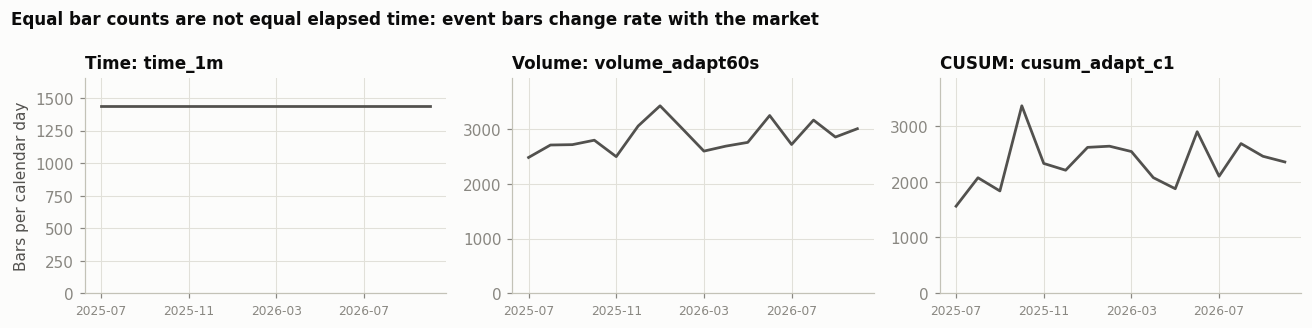

In [3]:
LIGHT = ["decision_time_ns", "t_start_ns", "eval_time_ns", "bar_close", "complete", "feed_complete", "last_trade_age_ms", "book_state"]
SURVEY = ["time_1m", "time_5m", "volume_50btc", "volume_adapt60s", "cusum_5bps", "cusum_10bps", "cusum_adapt_c1"]
SETS = {"Time": "time_1m", "Volume": "volume_adapt60s", "CUSUM": "cusum_adapt_c1"}
NAMES = list(SETS)

def spec_id(name):
    return next(k for k, v in man["bar_sets"].items() if v["name"] == name)

def load_bars(name, columns):
    # Column projection keeps memory small. Read-only access to the monthly parquet files.
    parts = [pq.read_table(f, columns=columns).to_pandas() for f in sorted((DATA / spec_id(name)).glob("*.parquet"))]
    b = pd.concat(parts, ignore_index=True)
    b.index = pd.DatetimeIndex(pd.to_datetime(b["decision_time_ns"], utc=True), name="t")
    return b

rows, LIGHTBARS, MONTHLY_BARS = [], {}, {}
for name in SURVEY:
    b = load_bars(name, LIGHT)
    use = b[(b.index >= TRAIN_START) & (b.index < DATA_END)]
    gap = np.diff(use["decision_time_ns"].to_numpy()) / 1e9
    daily = use.groupby(use.index.floor("D")).size()
    monthly = daily.groupby(daily.index.strftime("%Y-%m")).mean()          # mean bars per calendar day, month by month
    rows.append({"bar set": name, "bars": len(use), "median gap (s)": np.median(gap), "mean gap (s)": gap.mean(), "p99 gap (s)": np.quantile(gap, .99),
                 "bars per day": daily.median(), "daily count CV": daily.std() / daily.mean(), "monthly rate CV": monthly.std() / monthly.mean(),
                 "partial bars %": 100 * (use["complete"] != 1).mean(), "valid book %": 100 * use["book_state"].isin([0, 9]).mean()})
    if name in SETS.values():
        LIGHTBARS[name] = b
        MONTHLY_BARS[name] = monthly
    else:
        del b
SURVEY_TABLE = pd.DataFrame(rows).set_index("bar set")
display(SURVEY_TABLE.round({"median gap (s)": 1, "mean gap (s)": 1, "p99 gap (s)": 0, "bars per day": 0, "daily count CV": 3, "monthly rate CV": 3, "partial bars %": 2, "valid book %": 1}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, k in zip(axes, NAMES):
    s = MONTHLY_BARS[SETS[k]]
    ax.plot(range(len(s)), s.to_numpy(), color=INK2)
    ax.set_title(f"{k}: {SETS[k]}")
    ax.set_xticks(range(0, len(s), 4)); ax.set_xticklabels(s.index[::4], rotation=0, fontsize=8)
    ax.set_ylim(0, s.max() * 1.15)
axes[0].set_ylabel("Bars per calendar day")
fig.suptitle("Equal bar counts are not equal elapsed time: event bars change rate with the market", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

**The choices, and why.** The table decides these on sampling properties alone.

* **Time: `time_1m`.** It has the best valid-book coverage (97.2%, effectively equal to `time_5m`), it is the set the previous notebook studied, and it reacts within a minute. `time_5m` could react up to five minutes late, which is a real handicap for a rule that depends on the moment of a break.
* **Volume: `volume_adapt60s`.** The two volume sets are almost identical in speed (median gap 14.9 s against 14.4 s). Their day-to-day dispersion is also about the same (0.49 against 0.51), because the daily activity cycle dominates. What the adaptive threshold removes is slow drift: the **monthly** rate varies about half as much (CV 0.095 against 0.218). Over a 15-month walk-forward, that keeps the meaning of a bar stable. Its threshold uses strictly earlier days, so it is causal.
* **CUSUM: `cusum_adapt_c1`.** The monthly rate is far more stable than for the fixed thresholds (CV 0.190 against 0.55). A fixed 10 bps threshold can also go silent in quiet markets, with a 99th-percentile gap of 923 s against 358 s, which would delay the detection of a breakout. The cost is the lowest valid-book share of the three chosen sets (90.4%), because CUSUM bars fire in fast markets, when the book is most often stale. Section 7.3 shows how much that matters.

**Irregular durations.** `adapt60s` is the name of a threshold rule, not a bar length: the median gap is 14.9 s and the mean is 30.1 s. For CUSUM the median is 10.1 s, the mean 36.3 s, and the 99th percentile 358 s. The same number of bars can therefore span very different amounts of time. For that reason **nothing in this study is measured in bars**: lookbacks, cooldowns, holding periods, purging, overlap, and performance all use clock time or calendar days.

## 5. The shared trading layer

Three things are built once and used by every dataset: the 1-second tape, the volatility scale, and the funding schedule.

### 5.1 One-second trade tape

From all canonical trades, I keep the high, low, and last price of each second on the availability clock. Seconds with no trade stay empty, so a feed gap is visible and is never filled with a stale price.

In [4]:
SEC0 = int(pd.Timestamp("2025-06-28", tz=UTC).timestamp())
N_SEC = int(pd.Timestamp("2026-11-02", tz=UTC).timestamp()) - SEC0

@njit
def tape_add(sec, px, hi, lo, cl):
    # Prices are integer cents. A value of 0 means no trade in that second.
    for i in range(sec.size):
        s = sec[i]; p = px[i]
        if hi[s] == 0:
            hi[s] = p; lo[s] = p
        else:
            if p > hi[s]: hi[s] = p
            if p < lo[s]: lo[s] = p
        cl[s] = p

t_ = time.time()
HI = np.zeros(N_SEC, np.int32); LO = np.zeros(N_SEC, np.int32); CL = np.zeros(N_SEC, np.int32)
n_trades = 0
for f in sorted(TRADES.glob("*.parquet")):
    tb = pq.read_table(f, columns=["recv_ns", "price_e2"])
    ns = tb["recv_ns"].to_numpy()
    tape_add(ns // 10**9 - SEC0, tb["price_e2"].to_numpy().astype(np.int32), HI, LO, CL)
    n_trades += ns.size
print(f"Tape built from {n_trades:,} trades in {time.time() - t_:.0f} s, {HI.nbytes * 3 / 1e9:.2f} GB in memory.")

# Check against the dataset: the last trade before a minute boundary must equal that minute's close.
b1 = LIGHTBARS["time_1m"]
s_end = b1["decision_time_ns"].to_numpy() // 10**9 - 1 - SEC0
close_tape = CL[s_end] / 100.0
close_bar = b1["bar_close"].to_numpy()
both = (close_tape > 0) & np.isfinite(close_bar)
span = (b1.index >= TRAIN_START) & (b1.index < DATA_END)
print(f"Tape close equals time_1m close on {np.mean(np.abs(close_tape[both] - close_bar[both]) < 1e-6):.4%} of {both.sum():,} minutes.")
s0, s1 = int(TRAIN_START.timestamp()) - SEC0, int(DATA_END.timestamp()) - SEC0
print(f"Seconds with at least one trade, study window: {np.mean(HI[s0:s1] > 0):.2%}.")

Tape built from 1,771,277,674 trades in 92 s, 0.51 GB in memory.
Tape close equals time_1m close on 100.0000% of 672,872 minutes.
Seconds with at least one trade, study window: 95.47%.


### 5.2 Volatility scale and funding

The barrier scale and the trailing normalisers come from `time_1m` for **every** dataset, always using the last one-minute row at or before the decision. There are two reasons:

* **Comparability.** The same market state gives the same barrier width, whichever bars triggered the candidate.
* **Irregular bars.** A trailing average over event bars is weighted towards busy periods, because they contain more rows. A one-minute grid weights time equally.

Strict long-window columns are too sparse to use (the previous notebook found `rv_trade_24h` missing about 85% of the time), so realized variance is rebuilt from one-minute closes with a tolerance for partial windows, as in that notebook.

In [5]:
COMMON_COLS = ["decision_time_ns", "bar_close", "last_trade_age_ms", "funding_rate_asof", "notional_2m_usdt", "notional_15m_usdt", "trade_count_15m",
               "mean_trade_size_2m_btc", "depth_bid_10bps_btc", "depth_ask_10bps_btc", "tw_spread_bps_2m", "cost_buy_1000000usdt_atmid_bps",
               "cost_sell_1000000usdt_atmid_bps", "eff_spread_qw_bps_2m", "book_level_changes_2m"]

def safe_log(x):
    return np.log(x.where(x > 0))

def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

# Quantities normalised by their own trailing 7-day mean. One definition per name, shared with section 7.
REL_SOURCES = {
    "notional_2m": lambda b: b["notional_2m_usdt"], "notional_15m": lambda b: b["notional_15m_usdt"], "trades_15m": lambda b: b["trade_count_15m"],
    "trade_size_2m": lambda b: b["mean_trade_size_2m_btc"], "depth_10bps": lambda b: b["depth_bid_10bps_btc"] + b["depth_ask_10bps_btc"],
    "tw_spread_2m": lambda b: b["tw_spread_bps_2m"], "cost_1m": lambda b: (b["cost_buy_1000000usdt_atmid_bps"] + b["cost_sell_1000000usdt_atmid_bps"]) / 2,
    "eff_spread_2m": lambda b: b["eff_spread_qw_bps_2m"], "level_changes_2m": lambda b: b["book_level_changes_2m"]}

g = load_bars("time_1m", COMMON_COLS)
px = g["bar_close"].where(g["last_trade_age_ms"] <= FRESH_MS)
r2 = np.log(px).diff() ** 2
COMMON = {"t": g["decision_time_ns"].to_numpy(),
          "sig": np.sqrt(r2.rolling(240, min_periods=120).mean()).clip(lower=2e-5).to_numpy(),     # per-minute vol, as in the previous notebook
          "width": (BARRIER_K * np.sqrt(r2.rolling(VOL_MINUTES, min_periods=int(.8 * VOL_MINUTES)).mean() * (HORIZON_S / 60))).to_numpy()}
for lab, n in [("1h", 60), ("4h", 240), ("24h", 1440)]:
    COMMON[f"lrv_{lab}"] = safe_log(r2.rolling(n, min_periods=int(.8 * n)).sum()).to_numpy()
for name, fn in REL_SOURCES.items():
    # shift(1): the normaliser never contains the row it normalises.
    COMMON["norm_" + name] = safe_log(fn(g)).shift(1).rolling(7 * 1440, min_periods=1440).mean().to_numpy()

# Funding: the row stamped exactly at a settlement is evaluated 1 ns before it, so it holds the last rate known before settlement.
fund_times = pd.date_range("2025-06-28", "2026-11-01", freq="8h", tz=UTC)
fund_rate = g["funding_rate_asof"].ffill(limit=60).reindex(fund_times)
FUND_SEC = (fund_times.asi8 // 10**9 - SEC0).astype(np.int64)
FUND_CUM = np.concatenate([[0.0], np.cumsum(fund_rate.fillna(0.0).to_numpy() * 1e4)])    # bps paid by a long, cumulative
print(f"Funding settlements {len(fund_times):,}, rate unknown at {int(fund_rate.isna().sum())}. "
      f"Median {fund_rate.median() * 1e4:.2f} bps, 1% to 99% range {fund_rate.quantile(.01) * 1e4:.2f} to {fund_rate.quantile(.99) * 1e4:.2f} bps.")

width_bps = pd.Series(COMMON["width"] * 1e4, index=g.index)[TRAIN_START:DATA_END]
print(f"Barrier width (bps), 10th / 50th / 90th percentile: {width_bps.quantile(.1):.0f} / {width_bps.median():.0f} / {width_bps.quantile(.9):.0f}. "
      f"A {COST_RT_BPS:.0f} bps round trip is {COST_RT_BPS / width_bps.median():.0%} of the median barrier.")
del g, px, r2

Funding settlements 1,474, rate unknown at 4. Median 0.42 bps, 1% to 99% range -0.83 to 1.00 bps.
Barrier width (bps), 10th / 50th / 90th percentile: 45 / 80 / 129. A 10 bps round trip is 13% of the median barrier.


### 5.3 The exit engine, and proof that it behaves

One function resolves every candidate. It is used for labels **and** for simulated trades, so the two cannot drift apart. An error here would corrupt everything downstream, so I test it on synthetic price paths first, including the conservative rules: stop wins ties, gaps are paid in full, and a target needs a trade strictly through it.

In [6]:
NO_FILL, EXIT_PT, EXIT_SL, EXIT_TIME = 0, 1, 2, 3

@njit
def resolve(entry0, side, width, hi, lo, horizon, max_wait):
    # entry0: first tape second allowed for the fill. width: barrier distance in log return.
    n = entry0.size; N = hi.size
    reason = np.zeros(n, np.int8); ambiguous = np.zeros(n, np.bool_)
    e_sec = np.full(n, -1, np.int64); x_sec = np.full(n, -1, np.int64)
    e_px = np.full(n, np.nan); x_px = np.full(n, np.nan)
    for i in range(n):
        w = width[i]
        if not (w > 0.0):
            continue
        e = -1
        for s in range(entry0[i], min(entry0[i] + max_wait + 1, N)):
            if hi[s] > 0:
                e = s
                break
        if e < 0:
            continue                                  # nothing printed: not executable
        long_ = side[i] > 0
        ep = float(hi[e]) if long_ else float(lo[e])  # worst price in the fill second
        pt = ep * np.exp(w) if long_ else ep * np.exp(-w)
        sl = ep * np.exp(-w) if long_ else ep * np.exp(w)
        last = e + horizon
        if last >= N:
            continue
        done = False
        for s in range(e + 1, last + 1):
            if hi[s] == 0:
                continue                              # empty second: nothing observable
            if long_:
                t_sl = lo[s] <= sl
                t_pt = hi[s] > pt                     # strictly through the target
            else:
                t_sl = hi[s] >= sl
                t_pt = lo[s] < pt
            if t_sl:                                  # checked first: the stop wins any tie
                reason[i] = EXIT_SL; ambiguous[i] = t_pt; x_sec[i] = s
                x_px[i] = float(lo[s]) if long_ else float(hi[s])
                done = True
                break
            if t_pt:
                reason[i] = EXIT_PT; x_sec[i] = s; x_px[i] = pt
                done = True
                break
        if not done:
            s = last
            while s < N and hi[s] == 0:
                s += 1                                # a feed gap at the limit: first trade afterwards
            if s >= N:
                continue
            reason[i] = EXIT_TIME; x_sec[i] = s
            x_px[i] = float(lo[s]) if long_ else float(hi[s])
        e_sec[i] = e; e_px[i] = ep
    return reason, ambiguous, e_sec, e_px, x_sec, x_px

def one_trade(hi, lo, side, w=np.log(1.01) + 1e-12, horizon=20, wait=2):
    r, a, es, ep, xs, xp = resolve(np.array([1]), np.array([side]), np.array([w]), hi, lo, horizon, wait)
    gross = side * (xp[0] / ep[0] - 1) * 1e4 if r[0] else np.nan
    return dict(reason=int(r[0]), amb=bool(a[0]), ep=ep[0], xp=xp[0], x_sec=int(xs[0]), gross=gross)

def path():
    return np.full(40, 10_000, np.int32), np.full(40, 10_000, np.int32)

h, l = path(); h[5] = 10_200
o = one_trade(h, l, +1); assert o["reason"] == EXIT_PT and abs(o["gross"] - 100) < 1e-6              # long, target
h, l = path(); l[5] = 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_800 and o["gross"] < -100    # long, stop filled at the worst price
h, l = path(); h[5], l[5] = 10_200, 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["amb"]                                   # both touched: stop wins
h, l = path(); l[5] = 9_800
o = one_trade(h, l, -1); assert o["reason"] == EXIT_PT and o["gross"] > 0                             # short, price falls: profit
h, l = path(); h[5] = 10_200
o = one_trade(h, l, -1); assert o["reason"] == EXIT_SL and o["gross"] < 0                             # short, price rises: loss
h, l = path(); h[5], l[5] = 10_200, 9_800
o = one_trade(h, l, -1); assert o["reason"] == EXIT_SL and o["amb"] and o["gross"] < 0                # short tie: stop wins as well
h, l = path()
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME and o["x_sec"] == 21                         # time limit: entry second + horizon
h, l = path(); h[5] = 10_100
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME                                              # touching the target is not a fill
h, l = path(); h[5:10] = 0; l[5:10] = 0; l[10] = 9_500
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_500                           # gap through the stop is paid in full
h, l = path(); h[1:6] = 0; l[1:6] = 0
o = one_trade(h, l, +1); assert o["reason"] == NO_FILL                                                # no print within the wait: no trade
h, l = path(); h[1] = 10_050
o = one_trade(h, l, +1); assert o["ep"] == 10_050                                                     # buy fills at the worst price of the second
h, l = path(); l[1] = 9_950
o = one_trade(h, l, -1); assert o["ep"] == 9_950                                                      # sell fills at the worst price of the second
print("All 12 exit-engine tests passed.")

All 12 exit-engine tests passed.


## 6. Candidate events

The rule from section 3.2 runs on each bar set. Every window is clock time. Only the moments at which a bar closes differ, so one dataset can notice a breakout earlier than another. A candidate needs a complete bar with no trade gap and a fresh last trade.

**Eligibility, for every model and for the unfiltered comparison.** The filter must not get credit for skipping rows with bad data, so one common sample is used throughout. A candidate is eligible when, at decision time:

* the book is valid (`book_state` 0 or 9),
* the key trade-flow, order-flow, basis, open-interest, and liquidation windows are present,
* trailing volatility and volume normalisers exist,
* it is not near the known book incident,
* it can be filled.

This is the eligibility rule of the previous notebook. `book_state` is used as a filter only, never as a model input.

In [7]:
def find_candidates(b):
    t = b["decision_time_ns"].to_numpy()
    c = b["bar_close"].where(b["last_trade_age_ms"] <= FRESH_MS)
    # closed="left": the window is [t - 6h, t), so the current bar can never be part of its own channel.
    hi = c.rolling(CHANNEL, closed="left").max().to_numpy()
    lo = c.rolling(CHANNEL, closed="left").min().to_numpy()
    cv = c.to_numpy()
    first = np.searchsorted(t, t - CHANNEL_NS)
    ok = (t - t[first] >= MIN_SPAN_NS) & (b["complete"].to_numpy() == 1) & (b["feed_complete"].to_numpy() == 1) & np.isfinite(cv)
    picks = []
    for side, mask in ((1, ok & (cv > hi)), (-1, ok & (cv < lo))):
        last = None
        for i in np.flatnonzero(mask):
            if last is None or t[i] - last >= COOLDOWN_NS:            # clock-time cooldown, per side
                picks.append((i, side)); last = t[i]
    pos, side = np.array(picks).T
    order = np.argsort(pos, kind="stable"); pos, side = pos[order], side[order]
    E = pd.DataFrame({"pos": pos, "side": side, "t0_ns": t[pos], "t_start_ns": b["t_start_ns"].to_numpy()[pos], "eval_ns": b["eval_time_ns"].to_numpy()[pos],
                      "close": cv[pos], "edge": np.where(side > 0, hi[pos], lo[pos]), "chan_hi": hi[pos], "chan_lo": lo[pos]})
    return E[(E["t0_ns"] >= TRAIN_START.value) & (E["t0_ns"] < DATA_END.value)].reset_index(drop=True)

EV = {k: find_candidates(LIGHTBARS[SETS[k]]) for k in NAMES}
del LIGHTBARS

def attach_trades(E):
    # Resolve every candidate through the shared engine. The result serves as both label and simulated trade.
    E = E.copy()
    E["i1"] = np.searchsorted(COMMON["t"], E["t0_ns"].to_numpy(), side="right") - 1      # last one-minute row known at T
    assert (COMMON["t"][E["i1"].to_numpy()] <= E["t0_ns"].to_numpy()).all()
    E["width"] = COMMON["width"][E["i1"].to_numpy()]
    entry0 = (E["t0_ns"].to_numpy() + LATENCY_S * 10**9 + 10**9 - 1) // 10**9 - SEC0     # first whole second at or after T + latency
    reason, amb, e_sec, e_px, x_sec, x_px = resolve(entry0, E["side"].to_numpy(), E["width"].to_numpy(), HI, LO, HORIZON_S, MAX_WAIT_S)
    E["reason"], E["ambiguous"], E["e_sec"], E["e_px"], E["x_sec"], E["x_px"] = reason, amb, e_sec, e_px, x_sec, x_px
    E["fill_ok"] = reason != NO_FILL
    side = E["side"].to_numpy()
    E["gross_bps"] = side * (x_px / e_px - 1) * 1e4
    # Settlements strictly after entry and up to exit. A positive value is a cost, so a long pays a positive rate.
    i0, i1 = np.searchsorted(FUND_SEC, e_sec, side="right"), np.searchsorted(FUND_SEC, x_sec, side="right")
    E["fund_bps"] = side * (FUND_CUM[i1] - FUND_CUM[i0])
    E["net_bps"] = E["gross_bps"] - COST_RT_BPS - E["fund_bps"]
    E["y"] = (E["net_bps"] > 0).astype(np.int8)                                          # label in the direction of the trade, after all costs
    E["t1_ns"] = (x_sec + 1 + SEC0) * 10**9                                              # end of the exit second
    E["hold_min"] = (x_sec - e_sec) / 60.0
    return E

EV = {k: attach_trades(E) for k, E in EV.items()}
pd.DataFrame({k: {"candidates": len(E), "long share": E["side"].gt(0).mean(), "not fillable": int((~E["fill_ok"]).sum()),
                  "candidates per day": len(E) / ((DATA_END - TRAIN_START).days)} for k, E in EV.items()}).round(3)

,Time,Volume,CUSUM
candidates,3800.000,3659.000,3670.000
long share,0.503,0.501,0.502
not fillable,0.000,0.000,2.000
candidates per day,8.137,7.835,7.859


### Do the three datasets see the same events?

If they do, they are three views of one experiment and not three independent tests. This matters for how much weight agreement between them deserves. For each pair I measure the share of candidates with a same-side candidate in the other dataset within five minutes.

In [8]:
def overlap_share(a, b, tol_ns=5 * 60 * 10**9):
    hits = []
    for s in (1, -1):
        ta = a.loc[a["side"] == s, "t0_ns"].to_numpy(); tb = np.sort(b.loc[b["side"] == s, "t0_ns"].to_numpy())
        j = np.searchsorted(tb, ta)
        d = np.minimum(np.abs(ta - tb[np.clip(j - 1, 0, tb.size - 1)]), np.abs(tb[np.clip(j, 0, tb.size - 1)] - ta))
        hits.append(d <= tol_ns)
    return np.concatenate(hits).mean()

OVERLAP = pd.DataFrame({b_: {a_: overlap_share(EV[a_], EV[b_]) for a_ in NAMES} for b_ in NAMES})
OVERLAP.index.name = "share of these candidates"; OVERLAP.columns.name = "matched in"
display(OVERLAP.round(3))

# Detection speed: how far past the channel edge has the bar closed when the decision is made?
past_edge = pd.DataFrame({k: (E["side"] * np.log(E["close"] / E["edge"]) * 1e4).describe(percentiles=[.5, .9])[["50%", "90%"]] for k, E in EV.items()}).T
past_edge.columns = ["median bps past edge", "p90 bps past edge"]
past_edge.round(2)

matched in,Time,Volume,CUSUM
share of these candidates,,,
Time,1.000,0.757,0.732
Volume,0.786,1.000,0.891
CUSUM,0.758,0.889,1.000


,median bps past edge,p90 bps past edge
Time,2.67,12.85
Volume,1.21,3.61
CUSUM,2.01,4.70


**Interpretation.**

* **The rule behaves the same way on all three clocks.** Each gives about 3,700 candidates (3,659 to 3,800), about 8 per day, split evenly between long and short.
* **These are largely the same events.** Between time bars and either event-bar set, 73% to 79% of candidates have a same-side match within five minutes, and 89% do between Volume and CUSUM. **So the three datasets are not independent tests**, which is why the overall verdict requires at least two to pass.
* **Event bars do notice a break sooner.** At the decision, a time bar has closed a median of 2.7 bps past the edge, and 12.9 bps at the 90th percentile. Volume bars close 1.2 and 3.6 bps past it, and CUSUM bars 2.0 and 4.7 bps. This is the main structural difference between the datasets.

## 7. Features

### 7.1 What is reused, and what changed

The feature blocks come from the previous notebook's `build_features`. I made four kinds of change, all decided before any modelling.

| Change | Why |
|---|---|
| **Signed features are multiplied by the trade side** (prefix `s_`) | A metamodel must judge *this* trade. Positive `s_tfi_ratio_2m` means flow supports the trade, for a long and for a short. Without this, a model would have to rediscover the same logic separately for each side |
| **Bar-count windows and one-bar features are removed** | `rel_notional_1bar` is meaningless on volume bars, where every bar has about the same volume. Every feature now uses a clock window, so it means the same in all three datasets |
| **A compact set, chosen by economic role** | About 1,000 training events cannot support the previous notebook's 106 features. I keep the most representative windows of each family, without looking at any relation to outcomes. No target-based selection is used |
| **Breakout geometry added to the conventional set** | Distance past the channel, channel width, and time since the last candidate are plain price information. Leaving them out would weaken the baseline and flatter the extended model |

`z_vwap_dist_15m` moved from `FLOW` into the conventional set, because VWAP does not need aggressor side. That also makes the baseline harder to beat.

### 7.2 The two feature sets

| Set | Block | Content |
|---|---|---|
| **Conventional** | Trade | Side, breakout distance, channel width, time since last candidate |
| | Price | Past returns over 30 s to 24 h in volatility units, position in the 15-minute range, distance from VWAP |
| | Volatility | Realized variance over 2 minutes to 24 hours, barrier width |
| | Volume | Notional and trade count relative to the trailing 7-day mean, notional relative to the same time slot |
| | Calendar | Hour of day (two harmonics), day of week, weekend |
| **Extended** adds | `FLOW` | Signed trade flow, count imbalance, large-trade flow, trade size |
| | `BOOK_STATE` | Queue imbalance at three depths, cost skew, depth, spread, sweep cost |
| | `BOOK_FLOW` | OFI, multi-level OFI, pressure, adds versus removes, flow over depth, markout, effective spread, book activity |
| | `DERIV` | Perp–index basis and its changes, trade-versus-index return, funding, open-interest changes and level |
| | `LIQ` | Liquidation volume, signed liquidations, liquidation imbalance |

**Excluded on purpose:** `book_msg_count_*` (measures feed cadence), `tw_basis_*` and `funding_rz_7d` (coverage drifts over time), `rel_turnover_oi_15m` (a near copy of `rel_notional_15m`), and `book_state` and the certificate columns (quality metadata).

**Availability.** All dataset columns are as-of `eval_time`, which is before the decision. Trailing inputs come from the last one-minute row at or before the decision, and each normaliser is shifted so that it excludes its own row.

In [9]:
RAW_COLS = '''book_state ret_trade_30s ret_trade_2m ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h rv_trade_2m_grid1s rv_trade_15m_grid1s
close_location_15m drawdown_from_high_15m rebound_from_low_15m notional_2m_usdt notional_15m_usdt trade_count_15m notional_15m_vs_slot_median_28d vwap_distance_15m_bps
hour_of_day_sin hour_of_day_cos day_of_week_sin day_of_week_cos is_weekend
tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m count_imbalance_2m signed_large_flow_15m_usdt mean_trade_size_2m_btc
qi_1 qi_5bps qi_25bps depth_bid_10bps_btc depth_ask_10bps_btc tw_spread_bps_2m cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps
ofi_norm_30s ofi_norm_2m mlofi_norm_l5_30s pressure_net_5bps_2m tfi_over_tw_depth1_2m add_bid_10bps_2m_btc rem_bid_10bps_2m_btc add_ask_10bps_2m_btc rem_ask_10bps_2m_btc
markout_30s_qw_bps_2m eff_spread_qw_bps_2m book_level_changes_2m
basis_mark_index_bps basis_mark_index_change_15m_bps basis_mark_index_change_1h_bps ret_trade_minus_index_15m funding_rate_asof
oi_log_change_known_1h oi_log_change_known_4h oi_change_rz_7d oi_level_rz_7d
log1p_liq_notional_15m log1p_liq_notional_1h liq_signed_notional_15m_usdt liq_signed_notional_1h_usdt liq_imbalance_15m'''.split()

def read_rows(name, pos, columns):
    # Reads only candidate rows. pos are global row positions in file order.
    out, offset = [], 0
    for f in sorted((DATA / spec_id(name)).glob("*.parquet")):
        n = pq.ParquetFile(f).metadata.num_rows
        sel = pos[(pos >= offset) & (pos < offset + n)] - offset
        if sel.size:
            out.append(pq.read_table(f, columns=columns).take(pa.array(sel)).to_pandas())
        offset += n
    return pd.concat(out, ignore_index=True)

def candidate_features(E, R):
    s = E["side"].to_numpy(float)
    i = E["i1"].to_numpy()
    sig = COMMON["sig"][i]
    num = lambda c: R[c].to_numpy(float)
    zs = lambda x, minutes: x / (sig * np.sqrt(minutes))                  # volatility units, using trailing per-minute vol
    rel = lambda name: safe_log(REL_SOURCES[name](R)).to_numpy(float) - COMMON["norm_" + name][i]
    F = {}
    # ---- Conventional: the trade itself. Side stays a feature so long and short can differ.
    F["side"] = s
    F["z_break_excess"] = zs(np.abs(np.log(E["close"] / E["edge"]).to_numpy()), 60)
    F["z_channel_width"] = zs(np.log(E["chan_hi"] / E["chan_lo"]).to_numpy(), 360)
    F["l_since_prev_cand"] = np.log1p(np.diff(E["t0_ns"].to_numpy().astype(float), prepend=np.nan) / 3.6e12)
    # ---- Conventional: price
    for w, m in [("30s", .5), ("2m", 2), ("15m", 15), ("1h", 60), ("4h", 240), ("24h", 1440)]:
        F[f"s_z_ret_{w}"] = s * zs(num(f"ret_trade_{w}"), m)
    F["s_close_loc_15m"] = s * (2 * num("close_location_15m") - 1)
    below_high, above_low = -num("drawdown_from_high_15m"), num("rebound_from_low_15m")      # both are distances, at least zero
    F["z_adverse_15m"] = zs(np.where(s > 0, below_high, above_low), 15)                      # distance from the 15-minute extreme on the trade's side
    F["z_favorable_15m"] = zs(np.where(s > 0, above_low, below_high), 15)                    # distance already travelled in the trade's favour
    F["s_z_vwap_dist_15m"] = s * zs(num("vwap_distance_15m_bps") * 1e-4, 15)
    # ---- Conventional: volatility
    F["lrv_2m"], F["lrv_15m"] = safe_log(R["rv_trade_2m_grid1s"]).to_numpy(), safe_log(R["rv_trade_15m_grid1s"]).to_numpy()
    F["lrv_1h"], F["lrv_4h"], F["lrv_24h"] = COMMON["lrv_1h"][i], COMMON["lrv_4h"][i], COMMON["lrv_24h"][i]
    F["l_width"] = np.log(E["width"].to_numpy())                                             # sets how large costs are relative to the barrier
    # ---- Conventional: volume
    F["rel_notional_2m"], F["rel_notional_15m"], F["rel_trades_15m"] = rel("notional_2m"), rel("notional_15m"), rel("trades_15m")
    F["l_slot_notional_15m"] = safe_log(R["notional_15m_vs_slot_median_28d"]).to_numpy()
    # ---- Conventional: calendar
    hs, hc = num("hour_of_day_sin"), num("hour_of_day_cos")
    F["hour_sin"], F["hour_cos"], F["hour2_sin"], F["hour2_cos"] = hs, hc, 2 * hs * hc, hc ** 2 - hs ** 2
    F["dow_sin"], F["dow_cos"], F["is_weekend"] = num("day_of_week_sin"), num("day_of_week_cos"), num("is_weekend")
    # ---- FLOW: aggressor-signed trades
    for w in ["30s", "2m", "15m"]:
        F[f"s_tfi_ratio_{w}"] = s * num(f"tfi_ratio_{w}")
    F["s_count_imb_2m"] = s * num("count_imbalance_2m")
    F["s_large_flow_15m"] = s * num("signed_large_flow_15m_usdt") / num("notional_15m_usdt")
    F["rel_trade_size_2m"] = rel("trade_size_2m")
    # ---- BOOK_STATE
    for c in ["qi_1", "qi_5bps", "qi_25bps"]:
        F["s_" + c] = s * num(c)
    F["s_cost_skew_1m"] = s * (num("cost_buy_1000000usdt_atmid_bps") - num("cost_sell_1000000usdt_atmid_bps"))
    F["rel_depth_10bps"], F["rel_tw_spread_2m"], F["rel_cost_1m"] = rel("depth_10bps"), rel("tw_spread_2m"), rel("cost_1m")
    # ---- BOOK_FLOW
    for c, n in [("ofi_norm_30s", "s_ofi_30s"), ("ofi_norm_2m", "s_ofi_2m"), ("mlofi_norm_l5_30s", "s_mlofi_l5_30s"), ("pressure_net_5bps_2m", "s_pressure_2m"), ("tfi_over_tw_depth1_2m", "s_tfi_over_depth_2m")]:
        F[n] = s * num(c)
    ab, rb, aa, ra = num("add_bid_10bps_2m_btc"), num("rem_bid_10bps_2m_btc"), num("add_ask_10bps_2m_btc"), num("rem_ask_10bps_2m_btc")
    F["s_add_rem_imb_2m"] = s * (ab - rb - aa + ra) / (ab + rb + aa + ra)
    F["markout_30s_2m"] = num("markout_30s_qw_bps_2m")                    # adverse selection of recent takers: already sign-adjusted per trade
    F["rel_eff_spread_2m"], F["rel_level_changes_2m"] = rel("eff_spread_2m"), rel("level_changes_2m")
    # ---- DERIV
    F["s_basis_bps"] = s * num("basis_mark_index_bps")                    # positive: the trade buys a premium or sells a discount
    F["s_basis_chg_15m"], F["s_basis_chg_1h"] = s * num("basis_mark_index_change_15m_bps"), s * num("basis_mark_index_change_1h_bps")
    F["s_z_ret_vs_index_15m"] = s * zs(num("ret_trade_minus_index_15m"), 15)
    F["s_funding_bps"] = s * num("funding_rate_asof") * 1e4               # positive: the trade is on the side that pays
    F["oi_chg_1h"], F["oi_chg_4h"] = num("oi_log_change_known_1h"), num("oi_log_change_known_4h")
    F["oi_change_rz_7d"], F["oi_level_rz_7d"] = num("oi_change_rz_7d"), num("oi_level_rz_7d")
    # ---- LIQ. Signed liquidation is short minus long liquidated, so positive means forced buying.
    F["l_liq_15m"], F["l_liq_1h"] = num("log1p_liq_notional_15m"), num("log1p_liq_notional_1h")
    F["s_slog_liq_15m"], F["s_slog_liq_1h"] = s * slog(num("liq_signed_notional_15m_usdt")), s * slog(num("liq_signed_notional_1h_usdt"))
    F["s_liq_imb_15m"] = s * num("liq_imbalance_15m")
    return pd.DataFrame(F, index=E.index).replace([np.inf, -np.inf], np.nan)

BLOCKS = {
    "CONVENTIONAL": ["side", "z_break_excess", "z_channel_width", "l_since_prev_cand", "s_z_ret_30s", "s_z_ret_2m", "s_z_ret_15m", "s_z_ret_1h", "s_z_ret_4h", "s_z_ret_24h",
                     "s_close_loc_15m", "z_adverse_15m", "z_favorable_15m", "s_z_vwap_dist_15m", "lrv_2m", "lrv_15m", "lrv_1h", "lrv_4h", "lrv_24h", "l_width",
                     "rel_notional_2m", "rel_notional_15m", "rel_trades_15m", "l_slot_notional_15m", "hour_sin", "hour_cos", "hour2_sin", "hour2_cos", "dow_sin", "dow_cos", "is_weekend"],
    "FLOW": ["s_tfi_ratio_30s", "s_tfi_ratio_2m", "s_tfi_ratio_15m", "s_count_imb_2m", "s_large_flow_15m", "rel_trade_size_2m"],
    "BOOK_STATE": ["s_qi_1", "s_qi_5bps", "s_qi_25bps", "s_cost_skew_1m", "rel_depth_10bps", "rel_tw_spread_2m", "rel_cost_1m"],
    "BOOK_FLOW": ["s_ofi_30s", "s_ofi_2m", "s_mlofi_l5_30s", "s_pressure_2m", "s_tfi_over_depth_2m", "s_add_rem_imb_2m", "markout_30s_2m", "rel_eff_spread_2m", "rel_level_changes_2m"],
    "DERIV": ["s_basis_bps", "s_basis_chg_15m", "s_basis_chg_1h", "s_z_ret_vs_index_15m", "s_funding_bps", "oi_chg_1h", "oi_chg_4h", "oi_change_rz_7d", "oi_level_rz_7d"],
    "LIQ": ["l_liq_15m", "l_liq_1h", "s_slog_liq_15m", "s_slog_liq_1h", "s_liq_imb_15m"]}
CONV_COLS = BLOCKS["CONVENTIONAL"]
EXTRA_COLS = [c for b_, cols in BLOCKS.items() if b_ != "CONVENTIONAL" for c in cols]
ALL_COLS = CONV_COLS + EXTRA_COLS

DS = {}
for k in NAMES:
    E = EV[k]
    R = read_rows(SETS[k], E["pos"].to_numpy(), RAW_COLS)
    F = candidate_features(E, R)
    assert set(F.columns) == set(ALL_COLS) and len(F) == len(E)
    assert (E["eval_ns"] <= E["t0_ns"]).all()                       # features are evaluated no later than the decision
    # Eligibility: one common sample. book_state filters rows and never enters a model.
    ok = (R["book_state"].isin([0, 9]) & R["tfi_ratio_15m"].notna() & R["ofi_norm_2m"].notna() & R["basis_mark_index_bps"].notna()
          & R["oi_log_change_known_1h"].notna() & R["log1p_liq_notional_15m"].notna()).to_numpy()
    ok &= F["lrv_24h"].notna().to_numpy() & F["rel_notional_15m"].notna().to_numpy() & np.isfinite(COMMON["sig"][E["i1"].to_numpy()])
    incident = incident_rows(E["t_start_ns"].to_numpy() - 15 * 60 * 10**9, E["t0_ns"].to_numpy() + HORIZON_S * 10**9, man["quality_incidents"])
    E = E.assign(data_ok=ok & ~incident, eligible=ok & ~incident & E["fill_ok"].to_numpy(),
                 crash=(E["t1_ns"].to_numpy() >= CRASH_START.value) & (E["t0_ns"].to_numpy() < CRASH_END.value),
                 t0=pd.to_datetime(E["t0_ns"], utc=True))
    E["month"] = E["t0"].dt.strftime("%Y-%m")
    DS[k] = dict(E=E, X=F[ALL_COLS].to_numpy(float), y=E["y"].to_numpy(), net=E["net_bps"].to_numpy(), side=E["side"].to_numpy())
    del R
print({b_: len(c) for b_, c in BLOCKS.items()}, f"| conventional {len(CONV_COLS)}, extended {len(ALL_COLS)}")

{'CONVENTIONAL': 31, 'FLOW': 6, 'BOOK_STATE': 7, 'BOOK_FLOW': 9, 'DERIV': 9, 'LIQ': 5} | conventional 31, extended 67


### 7.3 Checks on the features and the sample

**Orientation.** Breakouts follow a move in the direction of the trade, so past return must be positive on average for **both** long and short candidates. If orientation had a sign error, one side would be negative. This uses features only.

**Coverage.** Eligibility is shown by month. This also shows how much the event-driven sets lose at the moments they fire most.

s_z_ret_15m  s_z_ret_1h  s_tfi_ratio_2m  s_ofi_2m  s_qi_5bps  s_slog_liq_15m
Time   long         1.423       1.064           0.363    55.497     -0.056           9.419
       short        1.459       1.108           0.360    56.348     -0.059           9.953
Volume long         1.475       1.105           0.409    59.389      0.007           8.727
       short        1.537       1.149           0.397    60.090     -0.010           9.577
CUSUM  long         1.439       1.093           0.384    57.133      0.108           8.574
       short        1.515       1.153           0.392    58.791      0.080           9.296

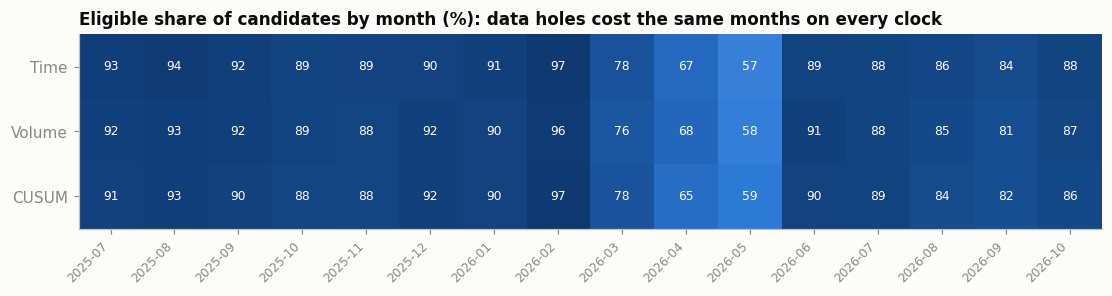

,candidates,eligible,eligible %,eligible before first test,eligible in test
Time,3800.0,3257.0,85.7,1246.0,1989.0
Volume,3659.0,3114.0,85.1,1193.0,1898.0
CUSUM,3670.0,3115.0,84.9,1184.0,1908.0


Largest missing shares among eligible candidates (%):


,Time,Volume,CUSUM
s_add_rem_imb_2m,8.3,7.1,7.1
s_qi_25bps,5.3,6.3,6.4
l_liq_1h,5.7,5.5,5.5
s_slog_liq_1h,5.7,5.5,5.5
s_basis_chg_15m,1.0,1.3,1.2


In [10]:
checks = ["s_z_ret_15m", "s_z_ret_1h", "s_tfi_ratio_2m", "s_ofi_2m", "s_qi_5bps", "s_slog_liq_15m"]
rows = {}
for k in NAMES:
    E, Xf = DS[k]["E"], pd.DataFrame(DS[k]["X"], columns=ALL_COLS)
    pre = (E["t0"] < FIRST_TEST).to_numpy() & E["eligible"].to_numpy()
    for s, lab in ((1, "long"), (-1, "short")):
        rows[(k, lab)] = Xf.loc[pre & (E["side"].to_numpy() == s), checks].mean()
ORIENT = pd.DataFrame(rows).T
display(ORIENT.round(3))
assert (ORIENT[["s_z_ret_15m", "s_z_ret_1h"]] > 0).all().all(), "orientation error"

ELIG_M = pd.DataFrame({k: DS[k]["E"].groupby("month")["eligible"].mean() * 100 for k in NAMES}).T
fig, ax = plt.subplots(figsize=(12, 2.3))
im = ax.imshow(ELIG_M.to_numpy(), cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(ELIG_M.shape[1])); ax.set_xticklabels(ELIG_M.columns, fontsize=8, rotation=45, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(ELIG_M.index); ax.grid(False)
for i in range(ELIG_M.shape[0]):
    for j in range(ELIG_M.shape[1]):
        v = ELIG_M.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 50 else INK)
ax.set_title("Eligible share of candidates by month (%): data holes cost the same months on every clock")
plt.show()

rows = {}
for k in NAMES:
    E = DS[k]["E"]
    rows[k] = {"candidates": len(E), "eligible": int(E["eligible"].sum()), "eligible %": 100 * E["eligible"].mean(),
               "eligible before first test": int((E["eligible"] & (E["t0"] < FIRST_TEST) & ~E["crash"]).sum()),
               "eligible in test": int((E["eligible"] & (E["t0"] >= FIRST_TEST) & (E["t0"] < TEST_END)).sum())}
display(pd.DataFrame(rows).T.round(1))
miss = pd.DataFrame({k: pd.DataFrame(DS[k]["X"][DS[k]["E"]["eligible"].to_numpy()], columns=ALL_COLS).isna().mean() * 100 for k in NAMES})
print("Largest missing shares among eligible candidates (%):")
miss.sort_values("CUSUM", ascending=False).head(5).round(1)

**A closer look at May 2026 `POST-HOC`.** May has the lowest eligibility in the chart, which a four-day reconnect storm cannot explain. I added this table after noticing that. It uses features only, on the one-minute grid.

In [11]:
# POST-HOC, features only: where does May 2026 lose its rows? The checks are the same main conditions as the eligibility rule.
MAY_COLS = ["decision_time_ns", "book_state", "tfi_ratio_15m", "ofi_norm_2m", "basis_mark_index_bps", "oi_log_change_known_1h", "log1p_liq_notional_15m"]
may = load_bars("time_1m", MAY_COLS).loc["2026-05"]
main_ok = may["book_state"].isin([0, 9]) & may[MAY_COLS[2:]].notna().all(axis=1)
span = pd.cut(may.index.day, [0, 17, 24, 27, 31], labels=["1-17 May", "18-24 May", "25-27 May", "28-31 May"])
MAY_TABLE = pd.DataFrame({"valid book_state %": may["book_state"].isin([0, 9]).groupby(span, observed=True).mean() * 100,
                          "ofi_norm_2m present %": may["ofi_norm_2m"].notna().groupby(span, observed=True).mean() * 100,
                          "main checks pass %": main_ok.groupby(span, observed=True).mean() * 100})
print(f"All of May 2026: {100 * main_ok.mean():.1f}% of minutes pass the main checks.")
MAY_TABLE.round(1)

All of May 2026: 70.5% of minutes pass the main checks.


,valid book_state %,ofi_norm_2m present %,main checks pass %
1-17 May,99.8,98.8,91.6
18-24 May,92.5,56.8,54.0
25-27 May,47.0,8.1,7.7
28-31 May,95.0,61.6,56.7


**Orientation passes.** Past returns are positive for both long and short candidates, at about 1.4 to 1.5 volatility units over 15 minutes, on all three datasets. Trade flow and order flow also point in the direction of the trade on both sides.

This table also shows something about the task. At the moment of a break, aggressive flow is almost always behind the move (`s_tfi_ratio_2m` near +0.4), and liquidations lean in the same direction. So the direction of flow cannot separate good breakouts from bad ones, because nearly all of them have it. Only its size can. Top-of-book imbalance, by contrast, is close to zero on average at these moments.

**Coverage.** About 85% of candidates are eligible on all three datasets, leaving 1,898 to 1,989 in the test window. Event bars lose about the same share as time bars overall, despite their weaker book coverage. Data problems are not spread evenly, though:

* **March and April 2026** reflect the book outage of 30 March to 9 April.
* **May 2026 is the lowest month, at 57% to 59%, and this is not only the reconnect storm.** The `POST-HOC` table above shows that `ofi_norm_2m`, which needs strict book coverage, starts failing on **18 May**, not on 24 May. It is present on just over half of minutes in 18–24 May (57%), almost never in 25–27 May (8%), and only partly recovered by month-end (62%). The audit report also places the peak of book gaps after 18 May. The previous notebook described this episode as 24–28 May, which understates how long it lasted.
* **Candidates lose more than ordinary rows.** In May, 70.5% of minutes pass the main checks but only 57% of time-bar candidates are eligible, which suggests that breakouts cluster when the book is under stress.

So the results below describe periods when the data was healthy, and they are thinner in spring 2026.

### 7.4 Overlap: research examples versus what can be held

Labels of overlapping candidates share the same price path, so 3,000 candidates are not 3,000 independent examples. I measure this on **clock time**: a bar-count version would overstate overlap in busy periods, when many bars pass in a few minutes.

* **Concurrency** is the number of label windows open at a moment.
* **Average uniqueness** of an event is its average share of the time it was alone, weighted by clock time. A value of 1 means it overlapped nothing.
* **Effective examples** is the sum of uniqueness, a rough count of independent labels.

These statistics use only events before the first test month.

In [12]:
def time_uniqueness(t0, t1):
    # Exact time-weighted average uniqueness on clock time, from sorted interval endpoints.
    t0 = np.asarray(t0, np.int64) // 10**6; t1 = np.asarray(t1, np.int64) // 10**6        # milliseconds
    pts = np.unique(np.concatenate([t0, t1]))
    delta = np.zeros(pts.size, np.int64)
    np.add.at(delta, np.searchsorted(pts, t0), 1); np.add.at(delta, np.searchsorted(pts, t1), -1)
    conc = np.cumsum(delta)[:-1]
    seg = np.diff(pts).astype(float)
    F_ = np.concatenate([[0.0], np.cumsum(seg / np.maximum(conc, 1) * (conc > 0))])
    u = (F_[np.searchsorted(pts, t1)] - F_[np.searchsorted(pts, t0)]) / np.maximum(t1 - t0, 1)
    return u, conc, seg

@njit
def greedy(t0, t1, keep):
    # The position policy: one position at a time. A candidate is taken only if it is kept and the book is flat at its decision time.
    taken = np.zeros(t0.size, np.bool_)
    free = np.int64(-1)
    for i in range(t0.size):
        if keep[i] and t0[i] >= free:
            taken[i] = True
            free = t1[i]
    return taken

rows = {}
for k in NAMES:
    E = DS[k]["E"]
    P_ = E[E["eligible"] & (E["t0"] < FIRST_TEST) & ~E["crash"]]
    u, conc, seg = time_uniqueness(P_["t0_ns"], P_["t1_ns"])
    busy = conc > 0
    taken = greedy(P_["t0_ns"].to_numpy(), P_["t1_ns"].to_numpy(), np.ones(len(P_), bool))
    rows[k] = {"research examples": len(P_), "mean concurrency when open": (conc[busy] * seg[busy]).sum() / seg[busy].sum(), "max concurrency": int(conc.max()),
               "mean uniqueness": u.mean(), "effective examples": u.sum(), "holdable positions, one at a time": int(taken.sum()),
               "holdable share": taken.mean(), "mean hold (min)": P_["hold_min"].mean()}
RESEARCH_VS_HELD = pd.DataFrame(rows).T
display(RESEARCH_VS_HELD.round(2))

# Label sanity on pre-test events. Gross returns must agree with the exit reason, on both sides.
P_ = pd.concat([DS[k]["E"].assign(ds=k) for k in NAMES])
P_ = P_[P_["eligible"] & (P_["t0"] < FIRST_TEST) & ~P_["crash"]]
assert (P_.loc[P_["reason"] == EXIT_PT, "gross_bps"] > 0).all() and (P_.loc[P_["reason"] == EXIT_SL, "gross_bps"] < 0).all()
LABEL_AUDIT = P_.groupby("ds").agg(events=("y", "size"), label_rate=("y", "mean"), target_exits=("reason", lambda r: (r == EXIT_PT).mean()), stop_exits=("reason", lambda r: (r == EXIT_SL).mean()),
                                   time_exits=("reason", lambda r: (r == EXIT_TIME).mean()), same_second_ties=("ambiguous", "sum"), median_barrier_bps=("width", lambda w: 1e4 * w.median()), mean_abs_funding_bps=("fund_bps", lambda f: f.abs().mean())).loc[NAMES]
display(LABEL_AUDIT.round(3))

,research examples,mean concurrency when open,max concurrency,mean uniqueness,effective examples,"holdable positions, one at a time",holdable share,mean hold (min)
Time,1246.0,1.39,4.0,0.74,920.53,732.0,0.59,168.04
Volume,1193.0,1.35,4.0,0.76,909.77,714.0,0.60,163.15
CUSUM,1184.0,1.35,4.0,0.76,904.26,708.0,0.60,164.15


,events,label_rate,target_exits,stop_exits,time_exits,same_second_ties,median_barrier_bps,mean_abs_funding_bps
ds,,,,,,,,
Time,1246,0.421,0.287,0.246,0.468,0,74.516,0.189
Volume,1193,0.413,0.280,0.271,0.449,0,74.427,0.183
CUSUM,1184,0.418,0.277,0.264,0.459,0,74.590,0.187


**Interpretation.**

* **Overlap is real but moderate.** While any label is open, 1.35 to 1.39 labels are open on average, and up to 4 at once. Mean uniqueness of 0.74 to 0.76 means that about 1,200 events carry the information of roughly 900.
* **Only about 60% of research examples can be held.** The rest fire while a position is already open. Metamodels learn from all examples, weighted by uniqueness, but the simulation in section 11 can hold only that smaller set.
* **Labels agree with exit reasons on both sides.** The assertion above confirms that every target exit is a gain and every stop is a loss.
* **Why fewer than half of labels are wins.** Target and stop exits are about equally common. Close to half of the trades reach the time limit instead, and a win must also clear 10 bps of costs. That gives a label rate near 42%.
* **The conservative tie rule was never needed.** No exit touched both barriers in the same second, so ambiguity was removed by the fine tape and not by a tie-break. With one-minute bars, this rule could have mattered.
* **Funding is small.** It averages about 0.2 bps per trade in absolute terms, because a trade lasts at most four hours and so crosses at most one settlement.

## 8. Walk-forward harness

One code path serves the main results, the shuffled-label control, and the placebo. For each monthly test fold it does the following:

1. Takes eligible events whose **actual exit** is at least 4 hours before the fold starts, removing the crash window.
2. Splits them in time: the earliest 70% for fitting, the latest 30% for calibration, separated by the same purge. Assertions below verify both purges on every fold.
3. Computes clock-time uniqueness weights separately inside each slice, from training events only.
4. Fits clipping, imputation, and scaling on the fit slice, and drops any column more than 30% missing there.
5. Fits the model on the fit slice.
6. On the calibration slice, fits Platt scaling and sets the budget threshold. The break-even threshold uses training labels.
7. Scores the test month. Nothing from that month enters any earlier step.

In [13]:
def wavg(x, w):
    return float(np.sum(x * w) / np.sum(w))

def wquantile(x, w, q):
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return float(x[o][np.searchsorted(c, q)])

def norm_w(u):
    return u / u.mean()

def make_folds(E):
    t0, t1 = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    usable = E["eligible"].to_numpy() & ~E["crash"].to_numpy()
    folds = []
    for fold in TEST_FOLDS:
        start = pd.Timestamp(f"{fold}-01", tz=UTC); end = start + pd.offsets.MonthBegin(1)
        tr = np.flatnonzero(usable & (t1 <= start.value - EMBARGO_NS))        # purge on the real label end, in clock time
        te = np.flatnonzero(E["eligible"].to_numpy() & (t0 >= start.value) & (t0 < end.value))
        cut = t0[tr[int(len(tr) * (1 - CAL_FRAC))]]
        fit, cal = tr[t1[tr] <= cut - EMBARGO_NS], tr[t0[tr] >= cut]
        assert t1[tr].max() <= start.value - EMBARGO_NS and t1[fit].max() <= t0[cal].min() - EMBARGO_NS and t0[te].min() >= start.value
        folds.append(dict(fold=fold, fit=fit, cal=cal, tr=tr, te=te, w_fit=norm_w(time_uniqueness(t0[fit], t1[fit])[0]),
                          w_cal=norm_w(time_uniqueness(t0[cal], t1[cal])[0]), w_tr=norm_w(time_uniqueness(t0[tr], t1[tr])[0])))
    return folds

def prep_fit(A):
    lo, hi = np.nanquantile(A, [.005, .995], axis=0)
    med = np.nanmedian(A, axis=0)
    Z = np.where(np.isnan(np.clip(A, lo, hi)), med, np.clip(A, lo, hi))
    return dict(lo=lo, hi=hi, med=med, mu=Z.mean(0), sd=Z.std(0), keep=(np.isnan(A).mean(0) <= MAX_MISSING) & (Z.std(0) > 1e-9))

def prep_apply(A, P):
    Z = np.clip(A, P["lo"], P["hi"]); Z = np.where(np.isnan(Z), P["med"], Z)
    return ((Z - P["mu"]) / np.where(P["sd"] > 0, P["sd"], 1.0))[:, P["keep"]]

def fit_lgb(Zf, yf, wf):
    d = lgb.Dataset(Zf, label=yf, weight=wf, free_raw_data=False)
    models = [lgb.train(dict(LGB_PARAMS, seed=s), d, LGB_ROUNDS) for s in LGB_SEEDS]
    return lambda A: np.mean([m.predict(A) for m in models], axis=0)

def fit_logit(Zf, yf, wf, Zc, yc, wc):
    # The penalty is the only parameter chosen, by weighted log loss on the calibration slice. Train-only.
    best, best_ll = None, np.inf
    for C_ in LOGIT_C:
        m = LogisticRegression(C=C_, max_iter=1000).fit(Zf, yf, sample_weight=wf)
        p = np.clip(m.predict_proba(Zc)[:, 1], 1e-6, 1 - 1e-6)
        ll = -wavg(yc * np.log(p) + (1 - yc) * np.log(1 - p), wc)
        if ll < best_ll:
            best, best_ll = m, ll
    return lambda A: best.predict_proba(A)[:, 1]

def platt_fit(s, y, w):
    # Monotone calibration. A non-positive slope means that the score carries no usable rank, so fall back to the base rate.
    z = logit(np.clip(s, 1e-6, 1 - 1e-6))[:, None]
    if y.min() == y.max():
        return 0.0, float(logit(np.clip(wavg(y, w), 1e-6, 1 - 1e-6)))
    m = LogisticRegression(C=1e6, max_iter=1000).fit(z, y, sample_weight=w)
    a, b = float(m.coef_[0, 0]), float(m.intercept_[0])
    return (a, b) if a > 0 else (0.0, float(logit(np.clip(wavg(y, w), 1e-6, 1 - 1e-6))))

def fit_predict(X, y, net, f, cols, kind):
    fit, cal, tr, te = f["fit"], f["cal"], f["tr"], f["te"]
    P = prep_fit(X[np.ix_(fit, cols)])
    Zf, Zc, Zt = (prep_apply(X[np.ix_(rows_, cols)], P) for rows_ in (fit, cal, te))
    score = fit_lgb(Zf, y[fit], f["w_fit"]) if kind == "lgb" else fit_logit(Zf, y[fit], f["w_fit"], Zc, y[cal], f["w_cal"])
    s_cal, s_te = score(Zc), score(Zt)
    a, b = platt_fit(s_cal, y[cal], f["w_cal"])
    p_te = expit(a * logit(np.clip(s_te, 1e-6, 1 - 1e-6)) + b)
    win = y[tr] == 1
    W, L = wavg(net[tr][win], f["w_tr"][win]), -wavg(net[tr][~win], f["w_tr"][~win])
    return dict(te=te, score=s_te, p=p_te, acc_budget=s_te >= wquantile(s_cal, f["w_cal"], 1 - BUDGET), acc_be=p_te >= L / (W + L),
                p0=wavg(y[tr], f["w_tr"]), p_star=L / (W + L), slope=a, kept=int(P["keep"].sum()))

def run_model(X, y, net, folds, cols, kind):
    parts = [fit_predict(X, y, net, f, cols, kind) for f in folds]
    return {key: np.concatenate([np.atleast_1d(np.full(p["te"].size, p[key]) if np.isscalar(p[key]) else p[key]) for p in parts])
            for key in ["te", "score", "p", "acc_budget", "acc_be", "p0", "p_star", "slope", "kept"]}

COL_IX = {c: i for i, c in enumerate(ALL_COLS)}
SET_COLS = {"CONV": [COL_IX[c] for c in CONV_COLS], "EXT": [COL_IX[c] for c in ALL_COLS]}
MODELS = [("lgb", "CONV"), ("lgb", "EXT"), ("log", "CONV"), ("log", "EXT")]
PRIMARY_CONV, PRIMARY_EXT = "lgb_CONV", "lgb_EXT"

t_ = time.time()
for k in NAMES:
    DS[k]["folds"] = make_folds(DS[k]["E"])
fold_sizes = pd.DataFrame({k: {f["fold"]: f"{f['fit'].size} / {f['cal'].size} / {f['te'].size}" for f in DS[k]["folds"]} for k in NAMES})
fold_sizes.index.name = "fold: fit / calibrate / test"
display(fold_sizes)

jobs = [(k, kind, fs) for k in NAMES for kind, fs in MODELS]
# Serial on purpose. Calling LightGBM from concurrent Python threads segfaulted inside lib_lightgbm during development.
res = [run_model(DS[k]["X"], DS[k]["y"], DS[k]["net"], DS[k]["folds"], SET_COLS[fs], kind) for k, kind, fs in jobs]

OOS = {}
for (k, kind, fs), r in zip(jobs, res):
    O = OOS.get(k)
    if O is None:
        O = DS[k]["E"].iloc[r["te"]].reset_index(drop=True)
        O["bin"] = np.where(O["t0"] >= REUSED_HOLDOUT_START, "Jun-Oct 2026", "Jan-May 2026")
    assert (O["pos"].to_numpy() == DS[k]["E"]["pos"].to_numpy()[r["te"]]).all()     # all models score exactly the same events
    tag = f"{kind}_{fs}"
    O["score_" + tag], O["p_" + tag], O["p0_" + tag] = r["score"], r["p"], r["p0"]
    O["acc_" + tag], O["be_" + tag], O["pstar_" + tag], O["slope_" + tag] = r["acc_budget"], r["acc_be"], r["p_star"], r["slope"]
    # Rank-matched acceptance: exactly the top half of each month. It uses the whole month's scores, so it is a diagnostic and not a tradable rule.
    O["rank_" + tag] = O.groupby("month")["score_" + tag].rank(pct=True, method="first") > 1 - BUDGET
    OOS[k] = O
print(f"Walk-forward finished in {time.time() - t_:.0f} s: {len(jobs)} model runs of {len(TEST_FOLDS)} folds.")

,Time,Volume,CUSUM
fold: fit / calibrate / test,,,
2026-01,866 / 374 / 219,832 / 358 / 208,826 / 355 / 212
2026-02,1022 / 440 / 213,978 / 421 / 200,974 / 419 / 204
2026-03,1170 / 503 / 180,1119 / 480 / 171,1115 / 480 / 173
2026-04,1300 / 558 / 155,1239 / 532 / 148,1239 / 532 / 143
2026-05,1406 / 604 / 137,1343 / 576 / 143,1339 / 575 / 146
2026-06,1504 / 645 / 205,1440 / 619 / 199,1442 / 618 / 200
2026-07,1648 / 707 / 226,1582 / 679 / 212,1581 / 679 / 221
2026-08,1804 / 775 / 216,1729 / 743 / 205,1736 / 745 / 200
2026-09,1951 / 839 / 204,1873 / 803 / 195,1876 / 805 / 190


Walk-forward finished in 34 s: 12 model runs of 10 folds.


### Evaluation tools

Inference runs on calendar days, so an event-rich day and a quiet day each count as one day, and elapsed time is treated the same way for every dataset.

* **Block bootstrap.** 5-day moving blocks over all calendar days in the test window, resampling every event on a chosen day together.
* **Daily series.** Loss differences and PnL are aggregated per calendar day, then tested with Newey–West.
* **Sharpe ratio.** Uses every calendar day, including days with no trade, annualised with 365 days.
* **Exposure.** Reported as time in market, and results are also given per hour in market.

In [14]:
def auc(y, s):
    r = stats.rankdata(s); n1 = int(y.sum()); n0 = y.size - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan

def hac_t(x, lags=5):
    # Mean and Newey-West t-statistic of a daily series.
    x = np.asarray(x, float); x = x[np.isfinite(x)]; n = x.size
    if n < 3:
        return np.nan, np.nan
    e = x - x.mean(); v = e @ e / n
    for L in range(1, min(lags, n - 1) + 1):
        v += 2 * (1 - L / (lags + 1)) * (e[L:] @ e[:-L]) / n
    return x.mean(), x.mean() / np.sqrt(max(v, 1e-30) / n)

CAL_DAYS = pd.date_range(FIRST_TEST, TEST_END, freq="D", inclusive="left")
N_DAYS = len(CAL_DAYS)

def day_index(t):
    return ((pd.to_datetime(t, utc=True) - FIRST_TEST) // pd.Timedelta(days=1)).to_numpy()

def boot_days(day, fn, reps=BOOT_REPS, block=5, seed=SEED):
    # Moving-block bootstrap over calendar days. fn receives the event positions of one resampled history.
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(day == d) for d in range(N_DAYS)]
    n_blocks = int(np.ceil(N_DAYS / block))
    out = np.empty(reps)
    for r in range(reps):
        starts = rng.integers(0, N_DAYS, n_blocks)
        days = ((starts[:, None] + np.arange(block)) % N_DAYS).ravel()[:N_DAYS]
        out[r] = fn(np.concatenate([groups[d] for d in days]))
    return out

def ci(a):
    return np.nanpercentile(a, [2.5, 97.5])

def log_loss_rows(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def daily_mean(values, day):
    # Calendar-day means. Days with no event are left out, since there is no forecast to score.
    return pd.Series(values).groupby(day).mean().to_numpy()

def daily_sum(values, day):
    return pd.Series(values).groupby(day).sum().reindex(range(N_DAYS), fill_value=0.0).to_numpy()

@njit
def mtm_max_drawdown(e_sec, x_sec, e_px, side, net, cl, half_cost, step):
    # Drawdown including open positions, marked on the tape every `step` seconds. Equity is in bps of notional.
    peak = 0.0; dd = 0.0; eq = 0.0
    for i in range(e_sec.size):
        for s in range(e_sec[i], x_sec[i], step):
            if cl[s] > 0:
                v = eq - half_cost + side[i] * (cl[s] / e_px[i] - 1.0) * 1e4
                if v > peak: peak = v
                if peak - v > dd: dd = peak - v
        eq += net[i]
        if eq > peak: peak = eq
        if peak - eq > dd: dd = peak - eq
    return dd

def simulate(O, keep, fee=COST_RT_BPS):
    # Applies the position policy to accepted candidates, then reports net of the given round-trip fee.
    taken = greedy(O["t0_ns"].to_numpy(), O["t1_ns"].to_numpy(), np.asarray(keep, bool))
    T_ = O[taken].copy()
    T_["net"] = T_["gross_bps"] - fee - T_["fund_bps"]
    return T_

def sim_stats(O, keep, fee=COST_RT_BPS):
    T_ = simulate(O, keep, fee)
    n = len(T_)
    r = {"accepted %": 100 * np.mean(keep), "trades": n}
    if n == 0:
        return r
    net = T_["net"].to_numpy()
    daily = daily_sum(net, day_index(T_["t1_ns"].clip(upper=TEST_END.value - 1)))
    hours = (T_["t1_ns"] - T_["t0_ns"]).sum() / 3.6e12
    months = T_.groupby("month")["net"].sum()
    wins, losses = net[net > 0].sum(), -net[net < 0].sum()
    r.update({"hit %": 100 * np.mean(net > 0), "gross/trade": T_["gross_bps"].mean(), "net/trade": net.mean(), "total net %": net.sum() / 100,
              "max DD %": mtm_max_drawdown(T_["e_sec"].to_numpy(), T_["x_sec"].to_numpy(), T_["e_px"].to_numpy(), T_["side"].to_numpy().astype(np.float64), net, CL, fee / 2, 60) / 100,
              "Sharpe": daily.mean() / daily.std() * np.sqrt(365) if daily.std() > 0 else np.nan, "profit factor": wins / losses if losses > 0 else np.nan,
              "market %": 100 * hours / (N_DAYS * 24), "net/hour held": net.sum() / hours, "months up": f"{int((months > 0).sum())}/{len(TEST_FOLDS)}"})
    return r

STRATS = {"Unfiltered": None, "Conventional": "acc_" + PRIMARY_CONV, "Extended": "acc_" + PRIMARY_EXT}
def keep_of(O, col):
    return np.ones(len(O), bool) if col is None else O[col].to_numpy()
print("Evaluation tools ready.")

Evaluation tools ready.


## 9. The unfiltered primary strategy `EXPLORATORY`

Before any filter, how does the rule behave on its own? This section reports the test window, January to October 2026, on the eligible sample.

Two views are shown because they answer different questions:

* **All research examples** is the average outcome if every candidate were entered, including overlapping ones. No account could hold all of these at once with fixed capital.
* **Executable** is what the one-position policy can actually hold.

In [15]:
def block_table(O, cols=("gross_bps", "fund_bps", "net_bps")):
    return {"n": len(O), "hit %": 100 * O["y"].mean(), "gross bps": O["gross_bps"].mean(), "funding cost bps": O["fund_bps"].mean(), "net bps": O["net_bps"].mean()}

rows = {}
for k in NAMES:
    O = OOS[k]
    allE = DS[k]["E"]; allE = allE[allE["fill_ok"] & (allE["t0"] >= FIRST_TEST) & (allE["t0"] < TEST_END)]
    rows[(k, "All candidates, ignoring eligibility")] = block_table(allE)
    rows[(k, "Eligible research examples")] = block_table(O)
    rows[(k, "  of which long")] = block_table(O[O["side"] > 0])
    rows[(k, "  of which short")] = block_table(O[O["side"] < 0])
    T_ = simulate(O, np.ones(len(O), bool))
    rows[(k, "Executable, one position at a time")] = block_table(T_)
PRIMARY_TABLE = pd.DataFrame(rows).T
display(PRIMARY_TABLE.round(2))

EXITS = pd.DataFrame({k: OOS[k]["reason"].map({EXIT_PT: "target", EXIT_SL: "stop", EXIT_TIME: "time limit"}).value_counts(normalize=True) * 100 for k in NAMES}).T
EXITS["same-second ties"] = [int(OOS[k]["ambiguous"].sum()) for k in NAMES]
EXITS["mean hold (min)"] = [OOS[k]["hold_min"].mean() for k in NAMES]
display(EXITS.round(1))

BOOT_PRIMARY = {}
for k in NAMES:
    T_ = simulate(OOS[k], np.ones(len(OOS[k]), bool))
    d = day_index(T_["t0"]); n_ = T_["net"].to_numpy(); g_ = T_["gross_bps"].to_numpy()
    BOOT_PRIMARY[k] = {"net/trade": n_.mean(), "net CI low": ci(boot_days(d, lambda i: n_[i].mean()))[0], "net CI high": ci(boot_days(d, lambda i: n_[i].mean()))[1],
                       "gross/trade": g_.mean(), "gross CI low": ci(boot_days(d, lambda i: g_[i].mean()))[0], "gross CI high": ci(boot_days(d, lambda i: g_[i].mean()))[1]}
display(pd.DataFrame(BOOT_PRIMARY).T.round(2))

# POST-HOC, added after the first evaluation. What does the worst-in-second fill rule cost, measured against the last trade of the same second?
rows = {}
for k in NAMES:
    T_ = simulate(OOS[k], np.ones(len(OOS[k]), bool))
    e_, x_, s_ = T_["e_sec"].to_numpy(), T_["x_sec"].to_numpy(), T_["side"].to_numpy()
    entry_cost = s_ * (T_["e_px"].to_numpy() / CL[e_] - 1) * 1e4
    exit_cost = s_ * (CL[x_] / T_["x_px"].to_numpy() - 1) * 1e4
    rows[k] = {"entry fill cost": entry_cost.mean(), "exit fill cost": exit_cost.mean(), "gross/trade as simulated": T_["gross_bps"].mean(),
               "gross/trade at last-trade prices": T_["gross_bps"].mean() + entry_cost.mean() + exit_cost.mean()}
FILL_COST = pd.DataFrame(rows).T
FILL_COST.round(2)

n  hit %  gross bps  funding cost bps  net bps
Time   All candidates, ignoring eligibility  2406.0  41.35      -3.02              0.02   -13.03
       Eligible research examples            1989.0  41.08      -3.01              0.02   -13.02
         of which long                       1018.0  38.70      -4.94              0.11   -15.06
         of which short                       971.0  43.56      -0.97             -0.08   -10.89
       Executable, one position at a time    1236.0  41.42      -3.95              0.03   -13.98
Volume All candidates, ignoring eligibility  2320.0  40.30      -3.77              0.01   -13.78
       Eligible research examples            1898.0  39.78      -4.30              0.02   -14.31
         of which long                        974.0  37.37      -6.60              0.11   -16.71
         of which short                       924.0  42.32      -1.86             -0.08   -11.79
       Executable, one position at a time    1189.0  40.12      -6.53              0.03   -16.56
CUSUM  All candidates, ignoring eligibility  2331.0  40.37      -3.82              0.01   -13.84
       Eligible research examples            1908.0  39.94      -4.23              0.02   -14.25
         of which long                        980.0  38.78      -5.40              0.11   -15.51
         of which short                       928.0  41.16      -2.99             -0.08   -12.91
       Executable, one position at a time    1197.0  39.68      -6.09              0.02   -16.11

reason,time limit,target,stop,same-second ties,mean hold (min)
Time,44.3,28.6,27.1,0,162.7
Volume,43.6,28.2,28.2,0,161.2
CUSUM,43.7,28.6,27.8,0,160.9


,net/trade,net CI low,net CI high,gross/trade,gross CI low,gross CI high
Time,-13.98,-17.87,-9.99,-3.95,-7.84,0.04
Volume,-16.56,-20.38,-12.82,-6.53,-10.35,-2.79
CUSUM,-16.11,-19.80,-12.42,-6.09,-9.79,-2.41


,entry fill cost,exit fill cost,gross/trade as simulated,gross/trade at last-trade prices
Time,0.62,0.84,-3.95,-2.49
Volume,1.11,0.70,-6.53,-4.73
CUSUM,1.07,0.67,-6.09,-4.35


**Interpretation.**

* **The strategy loses money on every view.** Between 1,189 and 1,236 trades can be held, with a net result of −14.0 to −16.6 bps per trade. All three 95% intervals are well below zero.
* **It was losing before fees as well.** Gross results are −4.0, −6.5, and −6.1 bps per trade. The Volume and CUSUM intervals exclude zero, and the Time interval just reaches it ([−7.8, +0.04]).
* **This is not caused by my conservative fills.** The `POST-HOC` table, added after seeing the results, measures the worst-in-second rule against the last trade of the same second. It costs 1.5 to 1.8 bps per trade, and at last-trade prices gross is still −2.5 to −4.7 bps.
* **There is no continuation to harvest.** Target and stop exits are almost equally common (about 28% each). If breakouts continued, targets would clearly outnumber stops.
* **Eligibility does not flatter the comparison.** Results on eligible candidates are within about 0.5 bps of results on all candidates (for example −13.0 against −13.0 on time bars).
* **The position policy does not rescue it.** Executable trades do slightly worse than the average research example.
* **Longs lost more than shorts** on all three datasets, which may partly reflect market drift. I did not test that, and the direction of a window's drift is not a stable edge in any case.

**Against my expectation.** I expected a loss after costs, because of the mild reversal found previously. I did not expect a clearly negative gross result on two of three datasets. So this pilot asks a hard version of the meta-labeling question: can a filter find a profitable subset of a strategy that loses money before costs?

## 10. Predictive results `EXPLORATORY`

The first question involves no trading: can the metamodels tell winning candidates from losing ones, and do the extra features help? All models score exactly the same events.

`AUC` measures ranking, with 0.5 meaning no skill. `log-loss skill` and `Brier skill` compare calibrated probabilities with a constant forecast equal to the training base rate, so 0 means no improvement and negative means worse than doing nothing. `precision` is the win rate of accepted candidates under the primary budget rule, and `lift` is that rate minus the win rate of all candidates.

In [16]:
LABEL = {"lgb_CONV": "LightGBM, conventional", "lgb_EXT": "LightGBM, extended", "log_CONV": "Logistic, conventional", "log_EXT": "Logistic, extended"}

def predictive_row(O, tag):
    y, p, p0 = O["y"].to_numpy(), O["p_" + tag].to_numpy(), O["p0_" + tag].to_numpy()
    acc = O["acc_" + tag].to_numpy()
    return {"events": len(O), "win rate %": 100 * y.mean(), "AUC": auc(y, p), "log-loss skill %": 100 * (1 - log_loss_rows(y, p).mean() / log_loss_rows(y, p0).mean()),
            "Brier skill %": 100 * (1 - np.mean((y - p) ** 2) / np.mean((y - p0) ** 2)), "accepted %": 100 * acc.mean(), "precision %": 100 * y[acc].mean() if acc.any() else np.nan,
            "lift pp": 100 * (y[acc].mean() - y.mean()) if acc.any() else np.nan}

rows = {(k, LABEL[f"{kind}_{fs}"]): predictive_row(OOS[k], f"{kind}_{fs}") for k in NAMES for kind, fs in MODELS}
PRED_TABLE = pd.DataFrame(rows).T
display(PRED_TABLE.round(2))

def compare(O, a, b, boot=True):
    # a = conventional, b = extended. Everything is paired on the same events.
    y = O["y"].to_numpy(); pa_, pb_ = O["p_" + a].to_numpy(), O["p_" + b].to_numpy(); net = O["net_bps"].to_numpy()
    d = day_index(O["t0"])
    d_loss = log_loss_rows(y, pa_) - log_loss_rows(y, pb_)              # positive means extended is better
    m, t = hac_t(daily_mean(d_loss, d))
    aA, aB = O["acc_" + a].to_numpy(), O["acc_" + b].to_numpy()
    rA, rB = O["rank_" + a].to_numpy(), O["rank_" + b].to_numpy()
    out = {"AUC conv": auc(y, pa_), "AUC ext": auc(y, pb_), "dAUC": auc(y, pb_) - auc(y, pa_), "daily dLogLoss x1000": 1000 * m, "DM t": t, "DM p (one-sided)": 1 - stats.norm.cdf(t),
           "net/accepted conv": net[aA].mean(), "net/accepted ext": net[aB].mean(), "net/matched conv": net[rA].mean(), "net/matched ext": net[rB].mean(),
           "d net matched": net[rB].mean() - net[rA].mean()}
    if boot:
        b_auc = boot_days(d, lambda i: auc(y[i], pb_[i]) - auc(y[i], pa_[i]))
        b_net = boot_days(d, lambda i: net[i][rB[i]].mean() - net[i][rA[i]].mean())
        out.update({"dAUC lo": ci(b_auc)[0], "dAUC hi": ci(b_auc)[1], "d net matched lo": ci(b_net)[0], "d net matched hi": ci(b_net)[1]})
        for lab, p_ in (("conv", pa_), ("ext", pb_)):
            lo_, hi_ = ci(boot_days(d, lambda i: auc(y[i], p_[i])))
            out.update({f"AUC {lab} lo": lo_, f"AUC {lab} hi": hi_})
    return out

CMP = pd.DataFrame({k: compare(OOS[k], PRIMARY_CONV, PRIMARY_EXT) for k in NAMES}).T
CMP["DM p Holm"] = multipletests(CMP["DM p (one-sided)"].to_numpy(), method="holm")[1]
CMP_LOG = pd.DataFrame({k: compare(OOS[k], "log_CONV", "log_EXT") for k in NAMES}).T
CMP_LOG["DM p Holm"] = multipletests(CMP_LOG["DM p (one-sided)"].to_numpy(), method="holm")[1]
show = ["AUC conv", "AUC ext", "dAUC", "dAUC lo", "dAUC hi", "DM t", "DM p Holm"]
print("Primary comparison, LightGBM, extended minus conventional:")
display(CMP[show].round(4))
print("Linear check, logistic regression, extended minus conventional:")
display(CMP_LOG[show].round(4))
print("Is each AUC distinguishable from 0.5? And selection value at exactly matched retention (net bps per accepted candidate, LightGBM):")
display(CMP[["AUC conv lo", "AUC conv hi", "AUC ext lo", "AUC ext hi", "net/matched conv", "net/matched ext", "d net matched", "d net matched lo", "d net matched hi"]].round(3))

events  win rate %   AUC  log-loss skill %  Brier skill %  accepted %  precision %  lift pp
Time   LightGBM, conventional  1989.0       41.08  0.56              0.92           1.20       48.06        46.03     4.95
       LightGBM, extended      1989.0       41.08  0.56              0.88           1.15       49.37        46.33     5.26
       Logistic, conventional  1989.0       41.08  0.54              0.25           0.33       48.72        45.20     4.13
       Logistic, extended      1989.0       41.08  0.53             -0.28          -0.37       48.72        44.07     2.99
Volume LightGBM, conventional  1898.0       39.78  0.55              0.66           0.84       48.05        44.19     4.41
       LightGBM, extended      1898.0       39.78  0.54              0.44           0.55       47.15        42.91     3.13
       Logistic, conventional  1898.0       39.78  0.54              0.22           0.28       47.05        44.01     4.23
       Logistic, extended      1898.0       39.78  0.53              0.11           0.14       47.15        42.35     2.57
CUSUM  LightGBM, conventional  1908.0       39.94  0.55              0.59           0.73       50.00        43.50     3.56
       LightGBM, extended      1908.0       39.94  0.53              0.31           0.36       50.26        44.00     4.07
       Logistic, conventional  1908.0       39.94  0.53              0.30           0.36       49.42        43.05     3.12
       Logistic, extended      1908.0       39.94  0.52              0.00          -0.02       50.26        42.13     2.19

Primary comparison, LightGBM, extended minus conventional:


,AUC conv,AUC ext,dAUC,dAUC lo,dAUC hi,DM t,DM p Holm
Time,0.5596,0.5570,-0.0025,-0.0174,0.0115,0.0153,1.0
Volume,0.5498,0.5406,-0.0092,-0.0259,0.0077,-0.3317,1.0
CUSUM,0.5458,0.5347,-0.0111,-0.0277,0.0050,-0.9634,1.0


Linear check, logistic regression, extended minus conventional:


,AUC conv,AUC ext,dAUC,dAUC lo,dAUC hi,DM t,DM p Holm
Time,0.5406,0.5266,-0.0140,-0.0286,0.0008,-1.8639,1.0
Volume,0.5377,0.5276,-0.0101,-0.0273,0.0075,-0.2827,1.0
CUSUM,0.5339,0.5203,-0.0136,-0.0311,0.0048,-1.1652,1.0


Is each AUC distinguishable from 0.5? And selection value at exactly matched retention (net bps per accepted candidate, LightGBM):


,AUC conv lo,AUC conv hi,AUC ext lo,AUC ext hi,net/matched conv,net/matched ext,d net matched,d net matched lo,d net matched hi
Time,0.532,0.588,0.529,0.588,-10.413,-9.220,1.193,-1.402,3.719
Volume,0.520,0.581,0.512,0.570,-12.080,-12.921,-0.840,-3.613,1.801
CUSUM,0.513,0.576,0.505,0.563,-12.607,-12.003,0.604,-2.398,4.119


**Interpretation.**

* **The metamodels have a little skill.** Conventional LightGBM reaches AUC 0.546 to 0.560, and its 95% intervals exclude 0.5. Accepted candidates win 3.6 to 5.0 percentage points more often than the average. Log-loss skill is small but positive (0.6% to 0.9%), meaning that the probabilities beat a constant forecast. Section 14 shows that this skill is not evenly spread over time.
* **The extended features add nothing measurable.** ΔAUC is −0.003, −0.009, and −0.011. All three intervals include zero, and their upper ends are only +0.005 to +0.011. On probability quality, the Diebold–Mariano t-statistics are 0.02, −0.33, and −0.96, with Holm-adjusted p-values of 1.0.
* **Selection value at matched retention does not differ.** Taking exactly the top half of each month, the extended model changes the net result by +1.2, −0.8, and +0.6 bps per candidate, with every interval spanning zero.
* **A linear model gives the same answer.** Logistic ΔAUC is −0.014, −0.010, and −0.014, and extended logistic log-loss skill is between −0.3% and +0.1%. The conclusion does not depend on the model class. The previous notebook's concern, that a linear baseline flatters extra features, does not arise here, since the extended model loses to both.

C1, C2, and C3 therefore fail on all three datasets.

### Does a higher score mean a better trade?

AUC is a summary. Here I split the test events into five equal groups by calibrated score and look directly at the average net result. A useful score should climb from left to right, and the right-hand end should sit above zero. The second figure checks calibration: whether predicted probabilities match realized win rates.

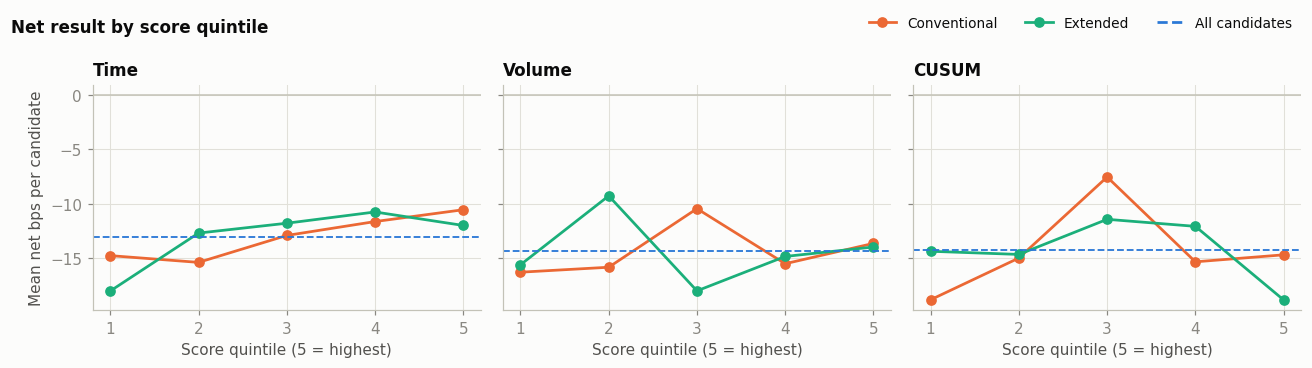

Q1    Q2    Q3    Q4    Q5
dataset model                                     
Time    Conventional -14.7 -15.4 -12.9 -11.6 -10.5
        Extended     -18.0 -12.7 -11.8 -10.7 -12.0
Volume  Conventional -16.3 -15.8 -10.4 -15.5 -13.6
        Extended     -15.6  -9.3 -18.0 -14.8 -13.9
CUSUM   Conventional -18.8 -15.0  -7.5 -15.3 -14.7
        Extended     -14.3 -14.6 -11.4 -12.1 -18.8

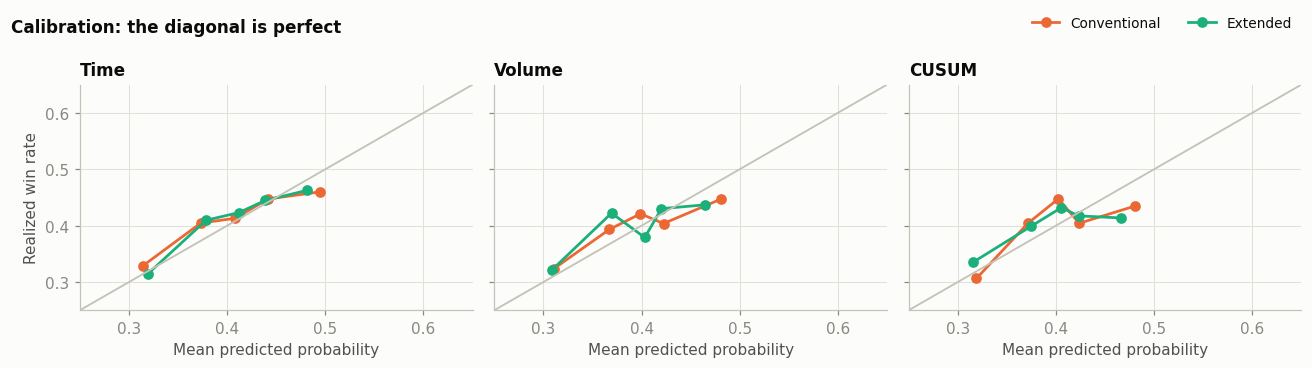

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
QUINT = {}
for ax, k in zip(axes, NAMES):
    O = OOS[k]
    for tag, lab in ((PRIMARY_CONV, "Conventional"), (PRIMARY_EXT, "Extended")):
        q = pd.qcut(O["p_" + tag].rank(method="first"), 5, labels=False) + 1
        m = O.groupby(q)["net_bps"].mean()
        QUINT[(k, lab)] = m
        ax.plot(m.index, m.to_numpy(), marker="o", ms=6, color=STRAT_COLOR[lab], label=lab)
    ax.axhline(O["net_bps"].mean(), color=C["blue"], lw=1.2, ls="--")
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(k); ax.set_xlabel("Score quintile (5 = highest)"); ax.set_xticks(range(1, 6))
axes[0].set_ylabel("Mean net bps per candidate")
handles = [plt.Line2D([], [], color=STRAT_COLOR[s], marker="o", label=s) for s in ("Conventional", "Extended")] + [plt.Line2D([], [], color=C["blue"], ls="--", label="All candidates")]
fig.legend(handles=handles, loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Net result by score quintile", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()
display(pd.DataFrame(QUINT).T.round(1).rename_axis(["dataset", "model"]).rename(columns=lambda c: f"Q{c}"))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True, sharex=True)
for ax, k in zip(axes, NAMES):
    O = OOS[k]
    for tag, lab in ((PRIMARY_CONV, "Conventional"), (PRIMARY_EXT, "Extended")):
        q = pd.qcut(O["p_" + tag].rank(method="first"), 5, labels=False)
        g_ = O.groupby(q).agg(p=("p_" + tag, "mean"), y=("y", "mean"))
        ax.plot(g_["p"], g_["y"], marker="o", ms=6, color=STRAT_COLOR[lab], label=lab)
    lim = [.25, .65]
    ax.plot(lim, lim, color=AXIS, lw=1.2); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xticks([.3, .4, .5, .6])
    ax.set_title(k); ax.set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Realized win rate")
fig.legend(handles=[plt.Line2D([], [], color=STRAT_COLOR[s], marker="o", label=s) for s in ("Conventional", "Extended")], loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Calibration: the diagonal is perfect", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

**Interpretation.**

* **Every quintile loses money.** All 30 cells in the table are negative, and the best is −7.5 bps. No score range here has a positive expected value after costs.
* **The score has only a weak link to net results.** Only conventional LightGBM on time bars rises almost steadily (−14.7 to −10.5 bps). The other curves are uneven, and on CUSUM the top quintile is worse than the middle one. Filtering by these scores lifts win rates by a few points, but that barely reaches the net result.
* **Neither model is reliably better at the top end.** The extended top quintile is worse than the conventional one on time bars and on CUSUM (−12.0 against −10.5, and −18.8 against −14.7), and about equal on volume bars.
* **Calibration is reasonable but overconfident at the top.** The lower quintiles sit near the diagonal, but the highest group predicts about 0.47 to 0.50 and realizes about 0.41 to 0.46. Break-even needs about 0.52, so the break-even rule will rarely fire, as the next section confirms.

## 11. Trading simulation `EXPLORATORY`

Now the same candidates go through the position policy of section 3.6, net of fees and funding, under the primary acceptance rule. `accepted %` is the share of candidates the filter passes. `trades` is what the position policy could then actually hold.

`total net %` and `max DD %` are percentages of one unit of notional. Drawdown includes open positions, marked to market every minute. `market %` is the share of clock time with a position. `net/hour held` puts strategies with very different exposure on one scale.

accepted %  trades  hit %  gross/trade  net/trade  total net %  max DD %  Sharpe  profit factor  market %  net/hour held months up
Time   Unfiltered        100.00    1236  41.42        -3.95     -13.98      -172.74    173.20   -7.29           0.63     44.41          -5.33      0/10
       Conventional       48.06     694  46.11        -0.53     -10.56       -73.29     75.04   -3.59           0.74     22.20          -4.52      2/10
       Extended           49.37     716  46.65        -0.16     -10.18       -72.88     76.08   -3.62           0.74     23.20          -4.30      2/10
Volume Unfiltered        100.00    1189  40.12        -6.53     -16.56      -196.88    197.73   -8.62           0.58     42.88          -6.29      0/10
       Conventional       48.05     678  44.25        -3.10     -13.11       -88.89     90.41   -4.51           0.68     22.07          -5.52      1/10
       Extended           47.15     666  43.09        -5.59     -15.61      -103.94    105.86   -6.08           0.63     21.21          -6.72      0/10
CUSUM  Unfiltered        100.00    1197  39.68        -6.09     -16.11      -192.85    193.93   -8.56           0.59     43.35          -6.10      0/10
       Conventional       50.00     693  43.72        -3.29     -13.30       -92.18     95.35   -4.64           0.68     22.52          -5.61      0/10
       Extended           50.26     695  44.03        -3.76     -13.77       -95.73     97.87   -5.50           0.66     22.74          -5.77      0/10

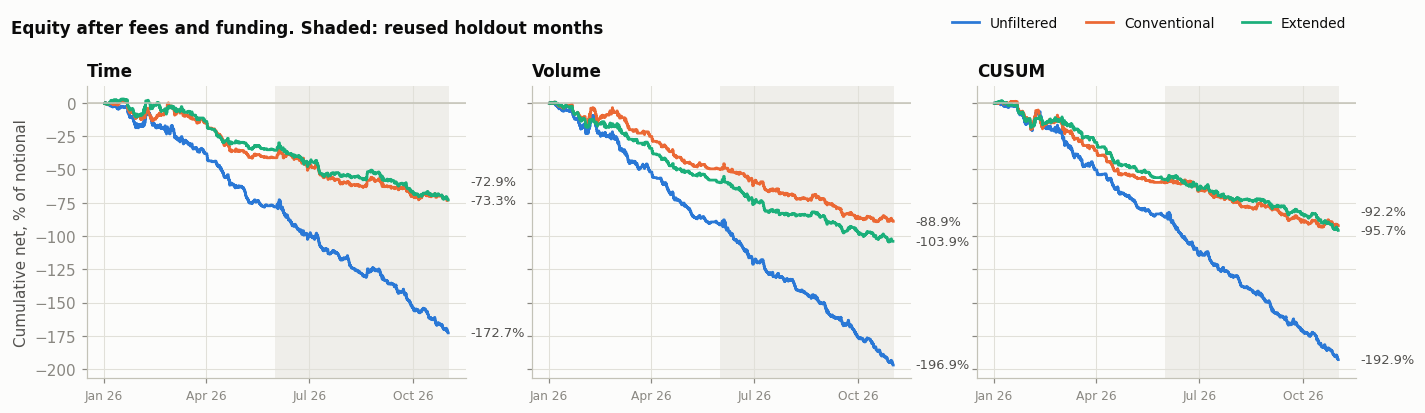

Secondary views. Break-even rule (LightGBM), and logistic regression under the fixed budget:


accepted %  trades  hit %  gross/trade  net/trade  total net %  max DD %  Sharpe  market %
Time   Break-even, conventional             4.02      68  47.06        -1.17     -11.20        -7.61      8.48   -1.32      1.78
       Break-even, extended                 1.91      34  41.18        -8.04     -18.03        -6.13      8.91   -1.45      0.87
       Logistic budget, conventional       48.72     720  44.72        -2.29     -12.32       -88.67     89.00   -4.51     23.33
       Logistic budget, extended           48.72     740  44.05        -3.91     -13.94      -103.13    103.72   -4.93     24.01
Volume Break-even, conventional             2.85      46  52.17         1.05      -8.92        -4.10      9.68   -0.81      1.27
       Break-even, extended                 1.37      26  42.31        -5.00     -15.07        -3.92      4.06   -1.34      0.64
       Logistic budget, conventional       47.05     661  43.72        -2.99     -13.01       -85.97     86.98   -4.37     21.59
       Logistic budget, extended           47.15     677  42.10        -6.55     -16.57      -112.19    112.48   -5.54     22.51
CUSUM  Break-even, conventional             1.68      27  55.56        18.25       8.19         2.21      2.71    0.91      0.70
       Break-even, extended                 1.47      24  33.33       -14.44     -24.38        -5.85      7.19   -2.07      0.80
       Logistic budget, conventional       49.42     694  43.23        -5.30     -15.30      -106.18    106.97   -5.67     22.44
       Logistic budget, extended           50.26     722  41.69        -7.03     -17.03      -122.95    123.77   -6.17     24.08

Mean break-even probability required by the rule: {'Time': 0.516, 'Volume': 0.52, 'CUSUM': 0.525}


In [18]:
rows = {(k, s): sim_stats(OOS[k], keep_of(OOS[k], col)) for k in NAMES for s, col in STRATS.items()}
SIM = pd.DataFrame(rows).T.infer_objects()
display(SIM.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.7), sharey=True)
ENDS = {}
for ax, k in zip(axes, NAMES):
    O = OOS[k]
    ENDS[k] = []
    for s, col in STRATS.items():
        T_ = simulate(O, keep_of(O, col))
        x = pd.to_datetime(T_["t1_ns"], utc=True); yv = T_["net"].cumsum() / 100
        ax.step(x, yv, where="post", color=STRAT_COLOR[s], label=s)
        ENDS[k].append(float(yv.iloc[-1]))
    if not DRY_RUN:
        ax.axvspan(REUSED_HOLDOUT_START, TEST_END, color="#efeeea", lw=0, zorder=0)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(k); ax.tick_params(axis="x", labelsize=8)
    ax.xaxis.set_major_locator(mpl.dates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
axes[0].set_ylabel("Cumulative net, % of notional")
fig.legend(handles=[plt.Line2D([], [], color=STRAT_COLOR[s], label=s) for s in STRATS], loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Equity after fees and funding. Shaded: reused holdout months", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(w_pad=4.0)
gap = 0.065 * (axes[0].get_ylim()[1] - axes[0].get_ylim()[0])
for ax, k in zip(axes, NAMES):
    # Final values as direct labels, nudged apart so that close lines stay readable.
    placed = []
    for v in sorted(ENDS[k]):
        y_ = v if not placed else max(v, placed[-1] + gap)
        placed.append(y_)
        ax.annotate(f"{v:+.1f}%", xy=(1.0, y_), xycoords=("axes fraction", "data"), xytext=(3, 0), textcoords="offset points", fontsize=8.5, color=INK2, va="center")
plt.show()

print("Secondary views. Break-even rule (LightGBM), and logistic regression under the fixed budget:")
rows = {}
for k in NAMES:
    O = OOS[k]
    rows[(k, "Break-even, conventional")] = sim_stats(O, O["be_" + PRIMARY_CONV].to_numpy())
    rows[(k, "Break-even, extended")] = sim_stats(O, O["be_" + PRIMARY_EXT].to_numpy())
    rows[(k, "Logistic budget, conventional")] = sim_stats(O, O["acc_log_CONV"].to_numpy())
    rows[(k, "Logistic budget, extended")] = sim_stats(O, O["acc_log_EXT"].to_numpy())
SIM2 = pd.DataFrame(rows).T.infer_objects()
display(SIM2[["accepted %", "trades", "hit %", "gross/trade", "net/trade", "total net %", "max DD %", "Sharpe", "market %"]].round(2))
print("Mean break-even probability required by the rule:", {k: round(float(OOS[k]["pstar_" + PRIMARY_EXT].mean()), 3) for k in NAMES})

**Reading the totals.** Totals below −100% mean more than the whole of one unit of notional was lost. With fixed notional and no compounding, these sums are bookkeeping for comparing strategies. A real account of one unit would have been wiped out before the end of the window.

**Interpretation.**

* **Both filters cut losses roughly in half.** Totals improve from −173%, −197%, and −193% to between −73% and −104%, and maximum drawdown improves in step. All of them stay deeply negative.
* **Time in market also halves,** from about 43% to about 22%. Per hour held, the picture is much less flattering. On time bars the loss per hour improves only from −5.3 to −4.5 and −4.3 bps. On CUSUM it barely moves (−6.1 to −5.6 and −5.8), and on volume bars the extended filter is **worse** than no filter (−6.7 against −6.3).
* **Net per trade improves by about 1 to 4 bps,** which is a small part of the 14 to 17 bps lost. Gross per trade stays negative for every filter.
* **Almost no month is profitable.** The filters make money in at most 2 of 10 months, and the unfiltered strategy in none.
* **Extended against conventional:** a difference of +0.4, −2.5, and −0.5 bps per trade, with no consistent sign.

**Secondary rules.**

* **Break-even rule: too few trades.** It accepts only 1.4% to 4.0% of candidates, for 24 to 68 trades, all below the 150-trade minimum. The results range from −24 to +8 bps per trade, which is noise. The one positive case (27 trades on CUSUM, conventional) should not be read as a finding.
* **Logistic regression under the fixed budget:** the extended filter is worse than the conventional one on all three datasets (−13.9 against −12.3, −16.6 against −13.0, and −17.0 against −15.3).

## 12. Better trades, or just fewer trades? `EXPLORATORY`

Any filter of a losing strategy looks good on total PnL, because it simply trades less. That proves nothing about skill. To separate the two, each filter is compared with a **random filter** that:

* accepts the same number of candidates in each month,
* passes through the same position policy,
* pays the same costs.

I draw 2,000 random filters per case. If the real filter's net per trade sits in the middle of that distribution, it did nothing that chance would not do. The p-value is the share of random filters at least as good.

trades  net/trade  unfiltered net/trade  random mean net/trade  random 95th pct  percentile vs random  p vs random  total net %  unfiltered total %  random mean total %                 verdict
Time   Conventional     694     -10.56                -13.98                 -13.41           -10.27                 93.00         0.07       -73.29             -172.74               -99.35   REDUCES EXPOSURE ONLY
       Extended         716     -10.18                -13.98                 -13.50           -10.36                 96.45         0.04       -72.88             -172.74              -102.06  IMPROVES TRADE QUALITY
Volume Conventional     678     -13.11                -16.56                 -15.15           -11.87                 84.80         0.15       -88.89             -196.88              -107.48   REDUCES EXPOSURE ONLY
       Extended         666     -15.61                -16.56                 -15.53           -12.33                 48.45         0.52      -103.94             -196.88              -108.54   REDUCES EXPOSURE ONLY
CUSUM  Conventional     693     -13.30                -16.11                 -15.06           -11.95                 82.70         0.17       -92.18             -192.85              -111.04   REDUCES EXPOSURE ONLY
       Extended         695     -13.77                -16.11                 -15.47           -12.34                 81.20         0.19       -95.73             -192.85              -114.36   REDUCES EXPOSURE ONLY

unfiltered total %  random mean total %  total net %  improvement  from lower exposure  from selection  exposure share %
Time   Conventional              -172.7                -99.4        -73.3         99.4                 73.4            26.1              73.8
       Extended                  -172.7               -102.1        -72.9         99.9                 70.7            29.2              70.8
Volume Conventional              -196.9               -107.5        -88.9        108.0                 89.4            18.6              82.8
       Extended                  -196.9               -108.5       -103.9         92.9                 88.3             4.6              95.0
CUSUM  Conventional              -192.9               -111.0        -92.2        100.7                 81.8            18.9              81.3
       Extended                  -192.9               -114.4        -95.7         97.1                 78.5            18.6              80.8

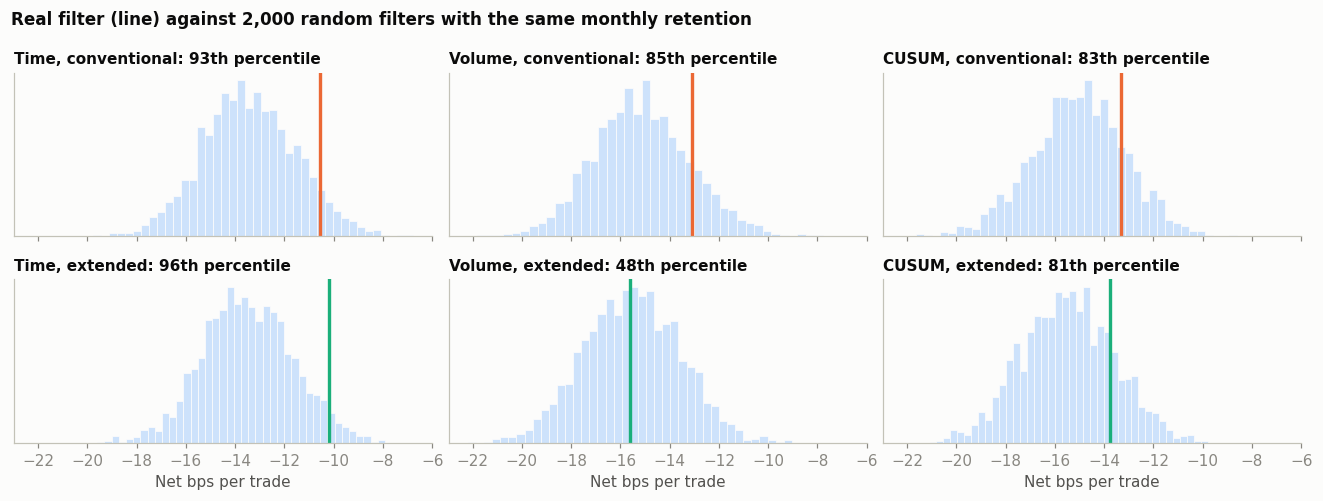

,net/trade conv,net/trade ext,difference,CI low,CI high,daily PnL diff t,trades shared,share of ext trades shared %
Time,-10.56,-10.18,0.38,-3.75,4.31,0.03,538.0,75.14
Volume,-13.11,-15.61,-2.50,-6.10,1.00,-1.21,526.0,78.98
CUSUM,-13.30,-13.77,-0.47,-4.69,4.23,-0.23,531.0,76.40


In [19]:
def random_benchmark(O, keep, reps=RANDOM_REPS, seed=SEED):
    rng = np.random.default_rng(seed)
    t0, t1 = O["t0_ns"].to_numpy(), O["t1_ns"].to_numpy()
    net = (O["gross_bps"] - COST_RT_BPS - O["fund_bps"]).to_numpy()
    groups = [(np.flatnonzero(O["month"].to_numpy() == m), int(keep[O["month"].to_numpy() == m].sum())) for m in TEST_FOLDS]
    per_trade, total, trades = np.empty(reps), np.empty(reps), np.empty(reps)
    for r in range(reps):
        mask = np.zeros(len(O), bool)
        for ix, n_keep in groups:
            mask[rng.choice(ix, n_keep, replace=False)] = True
        taken = greedy(t0, t1, mask)
        per_trade[r], total[r], trades[r] = net[taken].mean(), net[taken].sum(), taken.sum()
    return per_trade, total, trades

RAND, rows = {}, {}
for k in NAMES:
    O = OOS[k]
    base = sim_stats(O, np.ones(len(O), bool))
    for s in ("Conventional", "Extended"):
        keep = keep_of(O, STRATS[s]); st = sim_stats(O, keep)
        pt, tot, nt = random_benchmark(O, keep)
        RAND[(k, s)] = pt
        pct = 100 * np.mean(pt < st["net/trade"]); p = (1 + np.sum(pt >= st["net/trade"])) / (1 + pt.size)
        if st["trades"] < MIN_TRADES: verdict = "TOO FEW TRADES"
        elif st["net/trade"] > base["net/trade"] and pct >= 95: verdict = "IMPROVES TRADE QUALITY"
        elif st["total net %"] > base["total net %"]: verdict = "REDUCES EXPOSURE ONLY"
        else: verdict = "NO IMPROVEMENT"
        rows[(k, s)] = {"trades": st["trades"], "net/trade": st["net/trade"], "unfiltered net/trade": base["net/trade"], "random mean net/trade": pt.mean(), "random 95th pct": np.percentile(pt, 95),
                        "percentile vs random": pct, "p vs random": p, "total net %": st["total net %"], "unfiltered total %": base["total net %"], "random mean total %": tot.mean() / 100, "verdict": verdict}
QUALITY = pd.DataFrame(rows).T.infer_objects()
display(QUALITY.round(2))

# How much of the better total comes from simply trading less? A random filter with the same monthly retention isolates that part.
DECOMP = QUALITY[["unfiltered total %", "random mean total %", "total net %"]].astype(float).copy()
DECOMP["improvement"] = DECOMP["total net %"] - DECOMP["unfiltered total %"]
DECOMP["from lower exposure"] = DECOMP["random mean total %"] - DECOMP["unfiltered total %"]
DECOMP["from selection"] = DECOMP["total net %"] - DECOMP["random mean total %"]
DECOMP["exposure share %"] = 100 * DECOMP["from lower exposure"] / DECOMP["improvement"]
display(DECOMP.round(1))

fig, axes = plt.subplots(2, 3, figsize=(12, 4.6), sharex=True)
for j, k in enumerate(NAMES):
    for i, s in enumerate(("Conventional", "Extended")):
        ax = axes[i, j]; pt = RAND[(k, s)]; obs = float(QUALITY.loc[(k, s), "net/trade"])
        ax.hist(pt, bins=40, color="#cde2fb", edgecolor=SURFACE, linewidth=0.5)
        ax.axvline(obs, color=STRAT_COLOR[s], lw=2.2)
        ax.set_title(f"{k}, {s.lower()}: {QUALITY.loc[(k, s), 'percentile vs random']:.0f}th percentile", fontsize=10); ax.set_yticks([]); ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("Net bps per trade")
fig.suptitle("Real filter (line) against 2,000 random filters with the same monthly retention", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

# Head-to-head on simulated trades, as daily PnL differences.
rows = {}
for k in NAMES:
    O = OOS[k]
    TA, TB = simulate(O, keep_of(O, STRATS["Conventional"])), simulate(O, keep_of(O, STRATS["Extended"]))
    dA = daily_sum(TA["net"].to_numpy(), day_index(TA["t1_ns"].clip(upper=TEST_END.value - 1)))
    dB = daily_sum(TB["net"].to_numpy(), day_index(TB["t1_ns"].clip(upper=TEST_END.value - 1)))
    _, t = hac_t(dB - dA)
    both = len(np.intersect1d(TA["t0_ns"], TB["t0_ns"]))
    bn = {s: boot_days(day_index(T_["t0"]), lambda i, v=T_["net"].to_numpy(): v[i].mean()) for s, T_ in (("A", TA), ("B", TB))}
    lo, hi = ci(bn["B"] - bn["A"])          # both bootstraps share a seed, so they resample the same calendar days
    rows[k] = {"net/trade conv": TA["net"].mean(), "net/trade ext": TB["net"].mean(), "difference": TB["net"].mean() - TA["net"].mean(), "CI low": lo, "CI high": hi,
               "daily PnL diff t": t, "trades shared": both, "share of ext trades shared %": 100 * both / max(len(TB), 1)}
HEAD = pd.DataFrame(rows).T
display(HEAD.round(2))

**Interpretation.**

* **Most of the improvement is just trading less.** The decomposition table splits the gain in total result into two parts: what a random filter of the same size achieves, and what is left. Lower exposure explains **71% to 95%** of the improvement, so selection explains only 5% to 29%.
* **Five of six cases are `REDUCES EXPOSURE ONLY`.** On net per trade, these filters sit between the 48th and 93rd percentile of random filters. The extended filter on volume bars is at the 48th percentile, so it did exactly what chance would do.
* **One case is `IMPROVES TRADE QUALITY`: extended on time bars,** at the 96th percentile (p = 0.04). I report that as the rule requires, but it deserves little weight:
    * The p-value is not corrected for six comparisons. A Bonferroni bar would be 0.008.
    * The conventional filter on the same dataset is at the 93rd percentile, and the two differ by only 0.4 bps per trade.
    * The trade still loses 10.2 bps.
    * The same comparison fails on the other two datasets, which share most of these events.
* **No filter reaches break-even.** "Improves quality" here means "loses less per trade than chance would", not "profitable".
* **Head-to-head, extended and conventional cannot be separated.** The difference in net per trade is +0.4 [−3.8, +4.3], −2.5 [−6.1, +1.0], and −0.5 [−4.7, +4.2] bps, with daily PnL t-statistics of 0.03, −1.21, and −0.23. About three-quarters of their trades are the same trades, so their results were bound to be similar.

C4 passes only for time bars, and it passes on a 0.4 bps difference.

## 13. Controls `EXPLORATORY`

A method should fail when there is nothing to find. Two controls test that.

**Shuffled labels.** Training labels are randomly permuted, and the model is scored on the true test labels. AUC should fall to about 0.5. Anything clearly above that means information is leaking through the design.

**Placebo features.** This is the key calibration for the extended model. It keeps the conventional features and replaces all 36 additional features with **real values taken from other candidates of the same side, far away in time**. Their distributions and their time structure stay intact, but any link to the outcome is broken. The extended model has more inputs than the conventional one, so this measures what adding 36 irrelevant columns does to ΔAUC and to matched net selection value. Criterion C6 compares the observed ΔAUC with this distribution. There are 40 draws per dataset, so the 95th percentile is approximate.

Controls finished in 12.8 min: 120 placebo runs and 15 shuffled-label runs.


,Time,Volume,CUSUM
"shuffled-label AUC, mean",0.5056,0.4926,0.5026
"shuffled-label AUC, range",0.482 to 0.536,0.468 to 0.510,0.484 to 0.519
"placebo dAUC, mean",-0.0064,-0.0117,-0.0089
"placebo dAUC, sd",0.0068,0.0082,0.0079
"placebo dAUC, 95th pct",0.0035,-0.0004,0.0039
observed dAUC,-0.0025,-0.0092,-0.0111
observed percentile,67.5,60.0,37.5
"placebo d net matched, mean",-0.3518,-0.9817,-0.6687
"placebo d net matched, 95th pct",1.941,0.6659,0.8934
observed d net matched,1.1929,-0.8405,0.6044


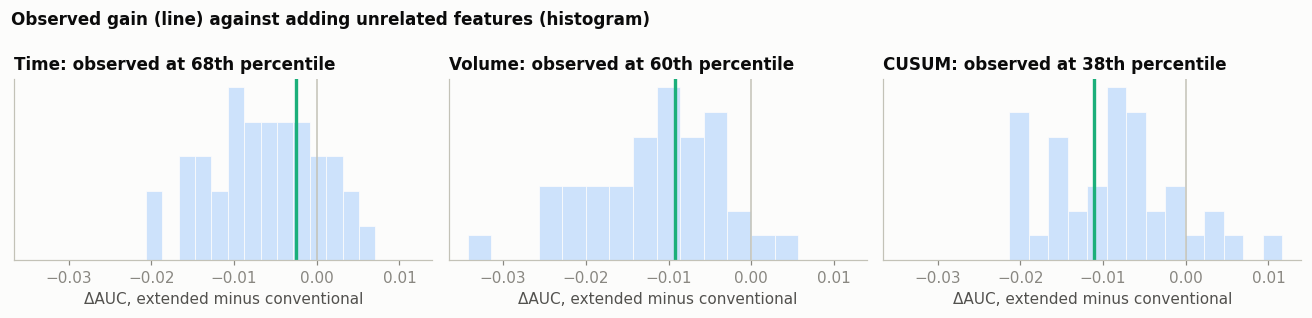

In [20]:
def rotate_extra(X, E, seed):
    # Moves the additional features between same-side candidates by a large random offset, so each keeps a real but unrelated vector.
    rng = np.random.default_rng(seed)
    Xp = X.copy(); extra = [COL_IX[c] for c in EXTRA_COLS]
    el = E["eligible"].to_numpy()
    for s in (1, -1):
        ix = np.flatnonzero(el & (E["side"].to_numpy() == s))
        shift = int(rng.integers(ix.size // 5, 4 * ix.size // 5))
        Xp[np.ix_(ix, extra)] = X[np.ix_(np.roll(ix, shift), extra)]
    return Xp

def placebo_job(k, X, y, net, E, folds, seed):
    Xp = rotate_extra(X, E, seed)
    return k, run_model(Xp, y, net, folds, SET_COLS["EXT"], "lgb")

def shuffle_job(k, X, y, net, folds, seed):
    yp = np.random.default_rng(seed).permutation(y)        # test labels stay true: they are only used for scoring below
    return k, run_model(X, yp, net, folds, SET_COLS["EXT"], "lgb")

t_ = time.time()
pj = [(k, SEED + 7919 * (j + 1) + 104729 * i) for i, k in enumerate(NAMES) for j in range(N_PLACEBO)]
PLACEBO = [placebo_job(k, DS[k]["X"], DS[k]["y"], DS[k]["net"], DS[k]["E"], DS[k]["folds"], s) for k, s in pj]
sj = [(k, SEED + 31 * (j + 1) + 1009 * i) for i, k in enumerate(NAMES) for j in range(N_SHUFFLE)]
SHUFFLED = [shuffle_job(k, DS[k]["X"], DS[k]["y"], DS[k]["net"], DS[k]["folds"], s) for k, s in sj]
print(f"Controls finished in {(time.time() - t_) / 60:.1f} min: {len(pj)} placebo runs and {len(sj)} shuffled-label runs.")

PL = {k: [] for k in NAMES}
for k, r in PLACEBO:
    O = OOS[k]; y = O["y"].to_numpy(); net = O["net_bps"].to_numpy()
    rank = pd.Series(r["score"]).groupby(O["month"].to_numpy()).rank(pct=True, method="first").to_numpy() > 1 - BUDGET
    conv_rank = O["rank_" + PRIMARY_CONV].to_numpy()
    st = sim_stats(O, r["acc_budget"])
    PL[k].append({"dAUC": auc(y, r["p"]) - auc(y, O["p_" + PRIMARY_CONV].to_numpy()), "d net matched": net[rank].mean() - net[conv_rank].mean(), "sim net/trade": st.get("net/trade", np.nan)})
PL = {k: pd.DataFrame(v) for k, v in PL.items()}

SH = {k: [] for k in NAMES}
for k, r in SHUFFLED:
    SH[k].append(auc(OOS[k]["y"].to_numpy(), r["score"]))

CTRL = pd.DataFrame({k: {"shuffled-label AUC, mean": np.mean(SH[k]), "shuffled-label AUC, range": f"{min(SH[k]):.3f} to {max(SH[k]):.3f}", "placebo dAUC, mean": PL[k]["dAUC"].mean(), "placebo dAUC, sd": PL[k]["dAUC"].std(),
                         "placebo dAUC, 95th pct": PL[k]["dAUC"].quantile(.95), "observed dAUC": CMP.loc[k, "dAUC"], "observed percentile": 100 * (PL[k]["dAUC"] < CMP.loc[k, "dAUC"]).mean(),
                         "placebo d net matched, mean": PL[k]["d net matched"].mean(), "placebo d net matched, 95th pct": PL[k]["d net matched"].quantile(.95), "observed d net matched": CMP.loc[k, "d net matched"],
                         "observed net percentile": 100 * (PL[k]["d net matched"] < CMP.loc[k, "d net matched"]).mean()} for k in NAMES}).T
display(CTRL.T.apply(lambda col: col.map(lambda v: round(v, 4) if isinstance(v, float) else v)))

fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), sharex=True)
for ax, k in zip(axes, NAMES):
    ax.hist(PL[k]["dAUC"], bins=14, color="#cde2fb", edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(CMP.loc[k, "dAUC"], color=C["aqua"], lw=2.2)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_title(f"{k}: observed at {CTRL.loc[k, 'observed percentile']:.0f}th percentile"); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("ΔAUC, extended minus conventional")
fig.suptitle("Observed gain (line) against adding unrelated features (histogram)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()

**Interpretation.**

* **The pipeline does not create signal.** With shuffled labels, AUC averages 0.506, 0.493, and 0.503. That is the expected result, so leakage through the design is unlikely.
* **The shuffled range is a useful scale.** Single draws run from 0.468 to 0.536, so noise alone moves AUC by about ±0.03 in this sample. Conventional AUC of 0.546 to 0.560 sits above that range, but not far above it.
* **The observed ΔAUC is what unrelated features produce.** It falls at the 68th, 60th, and 38th percentiles of the placebo distribution, far from the required 95th. C6 fails on all three datasets.
* **This explains the negative sign.** Adding 36 irrelevant columns by itself lowers AUC by 0.006 to 0.012 at this sample size. The real features do almost exactly the same: relative to the placebo mean, they differ by +0.004, +0.003, and −0.002, each well inside one placebo standard deviation (about 0.007 to 0.008). **So the extended features are not harmful. They behave as if they carried no extra information, and they pay the usual price for added dimensions.**
* **Selection value tells the same story,** at the 90th, 50th, and 85th percentiles.

With 40 draws, these percentiles are approximate, but none of the results is close enough to the threshold for that to matter.

## 14. Stability across time `EXPLORATORY`

An average can hide one good month. This section shows every test month, and it splits the test window into two blocks:

* **January–May 2026**: `EXPLORATORY`. Inside the previous notebook's development period.
* **June–October 2026**: `EXPLORATORY (reused holdout)`. Already examined once, on 2026-11-06.

Monthly AUC values rest on a few hundred dependent events each, so they are noisy. Consistency of sign tells more than any single cell.

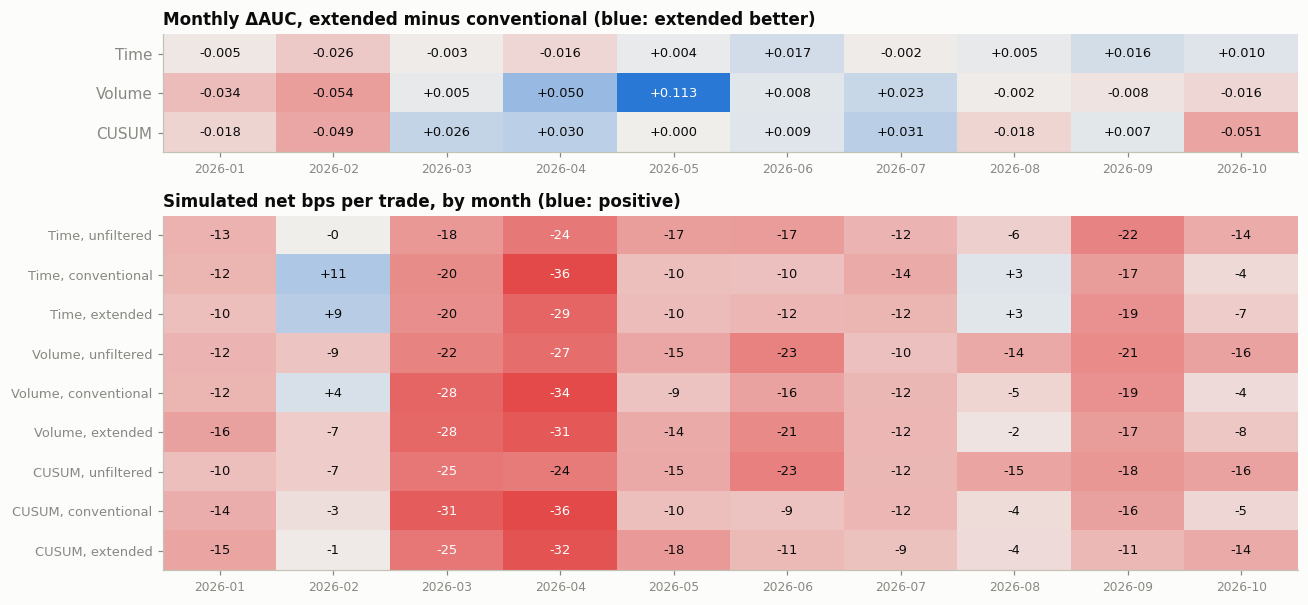

Monthly dAUC, with the count of months above zero:


,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,months > 0
Time,-0.005,-0.026,-0.003,-0.016,0.004,0.017,-0.002,0.005,0.016,0.010,5
Volume,-0.034,-0.054,0.005,0.050,0.113,0.008,0.023,-0.002,-0.008,-0.016,5
CUSUM,-0.018,-0.049,0.026,0.030,0.000,0.009,0.031,-0.018,0.007,-0.051,5


Simulated trades per month:


month                2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09  2026-10
Time   Unfiltered        136      128      115      103       89      129      136      135      130      135
       Conventional       82       66       63       59       48       74       82       75       73       72
       Extended           89       68       58       57       52       85       76       77       76       78
Volume Unfiltered        129      125      112       97       90      127      131      124      123      131
       Conventional       84       71       63       59       47       66       76       71       69       72
       Extended           78       58       62       59       52       75       71       59       72       80
CUSUM  Unfiltered        130      126      116       91       94      127      133      125      122      133
       Conventional       87       78       70       54       48       69       72       72       70       73
       Extended           77       65       70       59       49       71       78       67       76       83

tier  events    AUC  trades   hit %  net/trade  total net %
Time   Jan-May 2026 Unfiltered                     EXPLORATORY     904    NaN     571  42.907    -13.684      -78.134
                    Conventional                   EXPLORATORY     904  0.540     318  44.340    -12.950      -41.182
                    Extended                       EXPLORATORY     904  0.523     324  45.370    -10.988      -35.602
       Jun-Oct 2026 Unfiltered    EXPLORATORY (reused holdout)    1085    NaN     665  40.150    -14.226      -94.603
                    Conventional  EXPLORATORY (reused holdout)    1085  0.584     376  47.606     -8.540      -32.109
                    Extended      EXPLORATORY (reused holdout)    1085  0.588     392  47.704     -9.510      -37.277
Volume Jan-May 2026 Unfiltered                     EXPLORATORY     870    NaN     553  41.591    -16.525      -91.382
                    Conventional                   EXPLORATORY     870  0.515     324  43.210    -15.342      -49.707
                    Extended                       EXPLORATORY     870  0.491     309  41.100    -19.318      -59.693
       Jun-Oct 2026 Unfiltered    EXPLORATORY (reused holdout)    1028    NaN     636  38.836    -16.588     -105.497
                    Conventional  EXPLORATORY (reused holdout)    1028  0.589     354  45.198    -11.068      -39.180
                    Extended      EXPLORATORY (reused holdout)    1028  0.583     357  44.818    -12.395      -44.249
CUSUM  Jan-May 2026 Unfiltered                     EXPLORATORY     878    NaN     557  40.934    -15.376      -85.642
                    Conventional                   EXPLORATORY     878  0.504     337  41.840    -17.753      -59.826
                    Extended                       EXPLORATORY     878  0.491     320  41.562    -17.963      -57.481
       Jun-Oct 2026 Unfiltered    EXPLORATORY (reused holdout)    1030    NaN     640  38.594    -16.752     -107.210
                    Conventional  EXPLORATORY (reused holdout)    1030  0.587     356  45.506     -9.088      -32.353
                    Extended      EXPLORATORY (reused holdout)    1030  0.578     375  46.133    -10.199      -38.247

events  net/candidate  AUC conv  AUC ext   dAUC
Time   long   1018.0        -15.058     0.578    0.579  0.001
       short   971.0        -10.894     0.538    0.532 -0.006
Volume long    974.0        -16.714     0.576    0.565 -0.011
       short   924.0        -11.786     0.519    0.511 -0.008
CUSUM  long    980.0        -15.512     0.571    0.549 -0.022
       short   928.0        -12.910     0.517    0.518  0.001

In [21]:
M_AUC = {}
for k in NAMES:
    O = OOS[k]
    M_AUC[k] = pd.Series({m: auc(g_["y"].to_numpy(), g_["p_" + PRIMARY_EXT].to_numpy()) - auc(g_["y"].to_numpy(), g_["p_" + PRIMARY_CONV].to_numpy()) for m, g_ in O.groupby("month")})
M_AUC = pd.DataFrame(M_AUC).T.reindex(columns=TEST_FOLDS)

M_NET = {}
for k in NAMES:
    O = OOS[k]
    for s, col in STRATS.items():
        T_ = simulate(O, keep_of(O, col))
        M_NET[(k, s)] = T_.groupby("month")["net"].mean().reindex(TEST_FOLDS)
M_NET = pd.DataFrame(M_NET).T
M_TRADES = pd.DataFrame({(k, s): simulate(OOS[k], keep_of(OOS[k], col)).groupby("month").size().reindex(TEST_FOLDS).fillna(0) for k in NAMES for s, col in STRATS.items()}).T

fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), gridspec_kw=dict(height_ratios=[3, 9]))
ax = axes[0]
v = float(np.nanmax(np.abs(M_AUC.to_numpy())))
ax.imshow(M_AUC.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
for i in range(3):
    for j in range(M_AUC.shape[1]):
        val = M_AUC.iat[i, j]
        ax.text(j, i, f"{val:+.3f}", ha="center", va="center", fontsize=8.5, color="white" if abs(val) > .7 * v else INK)
ax.set_xticks(range(len(TEST_FOLDS))); ax.set_xticklabels(TEST_FOLDS, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(M_AUC.index); ax.grid(False)
ax.set_title("Monthly ΔAUC, extended minus conventional (blue: extended better)")
ax = axes[1]
vals = M_NET.to_numpy(); v = float(np.nanquantile(np.abs(vals), .98))
ax.imshow(vals, cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        val = vals[i, j]
        ax.text(j, i, "" if np.isnan(val) else f"{val:+.0f}", ha="center", va="center", fontsize=8.5, color="white" if abs(val) > .7 * v else INK)
ax.set_xticks(range(len(TEST_FOLDS))); ax.set_xticklabels(TEST_FOLDS, fontsize=8)
ax.set_yticks(range(vals.shape[0])); ax.set_yticklabels([f"{a}, {b.lower()}" for a, b in M_NET.index], fontsize=8.5); ax.grid(False)
ax.set_title("Simulated net bps per trade, by month (blue: positive)")
fig.tight_layout(); plt.show()

print("Monthly dAUC, with the count of months above zero:")
display(M_AUC.round(3).assign(**{"months > 0": (M_AUC > 0).sum(axis=1)}))
print("Simulated trades per month:")
display(M_TRADES.astype(int))

rows = {}
for k in NAMES:
    O = OOS[k]
    for b_ in sorted(O["bin"].unique()):
        o = O[O["bin"] == b_]
        tier = "EXPLORATORY (reused holdout)" if b_.startswith("Jun") else "EXPLORATORY"
        for s, col in STRATS.items():
            st = sim_stats(o, keep_of(o, col))
            rows[(k, b_, s)] = {"tier": tier, "events": len(o), "AUC": np.nan if col is None else auc(o["y"].to_numpy(), o["p_" + col.removeprefix("acc_")].to_numpy()),
                                "trades": st["trades"], "hit %": st.get("hit %"), "net/trade": st.get("net/trade"), "total net %": st.get("total net %")}
BLOCK_TABLE = pd.DataFrame(rows).T.infer_objects()
display(BLOCK_TABLE.round(3))

rows = {}
for k in NAMES:
    O = OOS[k]
    for side, lab in ((1, "long"), (-1, "short")):
        o = O[O["side"] == side]
        rows[(k, lab)] = {"events": len(o), "net/candidate": o["net_bps"].mean(), "AUC conv": auc(o["y"].to_numpy(), o["p_" + PRIMARY_CONV].to_numpy()), "AUC ext": auc(o["y"].to_numpy(), o["p_" + PRIMARY_EXT].to_numpy())}
SIDE_TABLE = pd.DataFrame(rows).T
SIDE_TABLE["dAUC"] = SIDE_TABLE["AUC ext"] - SIDE_TABLE["AUC conv"]
display(SIDE_TABLE.round(3))

**Interpretation.**

* **ΔAUC has no persistent sign.** It is positive in exactly 5 of 10 months on all three datasets, which is what a coin flip gives. The largest value, +0.113 on volume bars in May 2026, comes from the month with the thinnest and least reliable data (section 7.3), and it does not appear on the other two datasets. C5 fails everywhere.
* **Losses are persistent.** Only 5 of the 90 month-by-strategy cells are positive, in February and August 2026 and only for filters on time and volume bars. Spring is the worst stretch, and April 2026 is the worst month in eight of the nine rows.
* **Metamodel skill is not stable.** This is the most important pattern in the block table.

| AUC | Time | Volume | CUSUM |
|---|---|---|---|
| Conventional, Jan–May 2026 `EXPLORATORY` | 0.540 | 0.515 | 0.504 |
| Conventional, Jun–Oct 2026 `EXPLORATORY (reused holdout)` | 0.584 | 0.589 | 0.587 |
| Extended, Jan–May 2026 `EXPLORATORY` | 0.523 | 0.491 | 0.491 |
| Extended, Jun–Oct 2026 `EXPLORATORY (reused holdout)` | 0.588 | 0.583 | 0.578 |

On event bars, ranking skill in January–May is at or below chance. Almost all of the pooled AUC comes from June–October, the period that has already been examined, and also the period with more training data. The filters follow the same split. In June–October they improve net per trade by 4 to 8 bps. In January–May, gains are small or negative, and on CUSUM both filters are worse than no filter (−17.8 and −18.0 against −15.4 bps). With only two blocks, I cannot say whether more training data or a change in the market caused this.

* **The extended features are not better in either block.** They are 0.004 higher on time bars in June–October and lower in the other five comparisons.
* **Ranking is better on longs than on shorts** (AUC 0.57 to 0.58 against 0.52 to 0.54), but ΔAUC is near zero or negative on both sides, so the extended features do not help on either.

### Which features does the extended model use?

This is description, not evidence. I refit the extended LightGBM once per dataset on the fit slice of the last fold, and sum gain by block. Gain shows where trees split, and with weak signals trees also split on noise. Block size matters too, so I compare each block's share of gain with its share of columns.

In [22]:
rows = {}
for k in NAMES:
    D_, f = DS[k], DS[k]["folds"][-1]
    P = prep_fit(D_["X"][np.ix_(f["fit"], SET_COLS["EXT"])])
    Zf = prep_apply(D_["X"][np.ix_(f["fit"], SET_COLS["EXT"])], P)
    names = np.array(ALL_COLS)[P["keep"]]
    d = lgb.Dataset(Zf, label=D_["y"][f["fit"]], weight=f["w_fit"], feature_name=list(names), free_raw_data=False)
    gain = np.mean([lgb.train(dict(LGB_PARAMS, seed=s), d, LGB_ROUNDS).feature_importance("gain") for s in LGB_SEEDS], axis=0)
    s_ = pd.Series(gain, index=names)
    rows[k] = {b_: 100 * s_.reindex(cols).sum() / s_.sum() for b_, cols in BLOCKS.items()}
    rows[k]["top 5 features"] = ", ".join(s_.sort_values(ascending=False).head(5).index)
GAIN = pd.DataFrame(rows).T
GAIN_SHARE = GAIN.drop(columns="top 5 features").astype(float).T
GAIN_SHARE["share of columns %"] = [100 * len(BLOCKS[b_]) / len(ALL_COLS) for b_ in GAIN_SHARE.index]
display(GAIN_SHARE.round(1))
GAIN[["top 5 features"]]

,Time,Volume,CUSUM,share of columns %
CONVENTIONAL,53.9,50.7,51.1,46.3
FLOW,4.4,10.2,9.4,9.0
BOOK_STATE,7.9,7.5,8.0,10.4
BOOK_FLOW,13.7,15.1,14.1,13.4
DERIV,15.6,11.6,13.3,13.4
LIQ,4.4,4.9,4.1,7.5


,top 5 features
Time,"dow_sin, hour_cos, dow_cos, s_ofi_30s, oi_change_rz_7d"
Volume,"dow_sin, rel_level_changes_2m, hour_cos, dow_cos, s_tfi_ratio_15m"
CUSUM,"dow_sin, dow_cos, hour_cos, s_tfi_ratio_15m, lrv_2m"


**Interpretation.** No additional block stands out. Each one's share of gain is close to, or below, its share of columns, and the conventional block takes slightly more than its share (51% to 54% against 46%). `LIQ` and `BOOK_STATE` are the weakest relative to their size. So the derivatives features, the main open question of this pilot, were not used noticeably more than their column count would suggest.

Calendar features lead the list on every dataset. That is a warning and not a discovery. Day-of-week and hour effects estimated from a few months rest on few independent weeks, and they have the weakest economic justification here. Part of the conventional model's skill may be this kind of fit. I did not test that, because removing these features after seeing the results would be exactly the kind of search this pilot rules out.

## 15. Sensitivity to costs `EXPLORATORY`

The labels, models, and thresholds stay exactly as trained at 10 bps. Only the fee charged in the simulation changes, so this shows how the same trades would score under other cost assumptions. 4 bps is the all-maker case, which assumes fills that a breakout strategy could rarely get. 7 bps mixes maker and taker. 10 bps is the base case. 14 bps adds some slippage.

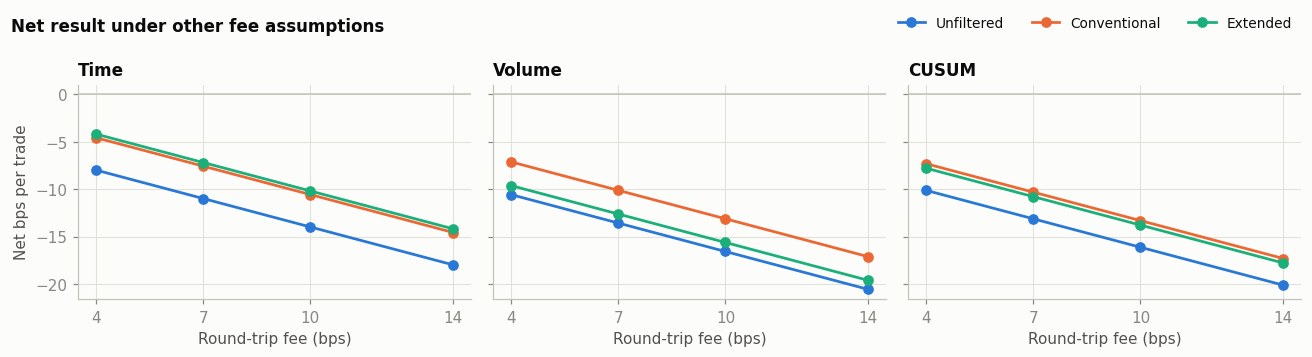

round trip bps         4.0    7.0    10.0   14.0
dataset strategy                                
Time    Unfiltered    -7.98 -10.98 -13.98 -17.98
        Conventional  -4.56  -7.56 -10.56 -14.56
        Extended      -4.18  -7.18 -10.18 -14.18
Volume  Unfiltered   -10.56 -13.56 -16.56 -20.56
        Conventional  -7.11 -10.11 -13.11 -17.11
        Extended      -9.61 -12.61 -15.61 -19.61
CUSUM   Unfiltered   -10.11 -13.11 -16.11 -20.11
        Conventional  -7.30 -10.30 -13.30 -17.30
        Extended      -7.77 -10.77 -13.77 -17.77

In [23]:
rows = {}
for k in NAMES:
    for s, col in STRATS.items():
        for fee in COST_GRID:
            st = sim_stats(OOS[k], keep_of(OOS[k], col), fee)
            rows[(k, s, fee)] = {"net/trade": st["net/trade"], "total net %": st["total net %"]}
COST = pd.DataFrame(rows).T.sort_index()
COST.index.names = ["dataset", "strategy", "round trip bps"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, k in zip(axes, NAMES):
    for s in STRATS:
        c_ = COST.loc[(k, s)]
        ax.plot(c_.index, c_["net/trade"], marker="o", ms=6, color=STRAT_COLOR[s], label=s)
    ax.axhline(0, color=AXIS, lw=1); ax.set_title(k); ax.set_xlabel("Round-trip fee (bps)"); ax.set_xticks(COST_GRID)
axes[0].set_ylabel("Net bps per trade")
fig.legend(handles=[plt.Line2D([], [], color=STRAT_COLOR[s], marker="o", label=s) for s in STRATS], loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Net result under other fee assumptions", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); plt.show()
display(COST["net/trade"].unstack("round trip bps").reindex(pd.MultiIndex.from_product([NAMES, list(STRATS)], names=["dataset", "strategy"])).round(2))

**Interpretation.** No fee assumption changes the conclusion. Every strategy on every dataset loses money even at 4 bps round trip (−4.2 to −10.6 bps per trade). Since gross results are negative, even zero fees would not help. A fee is subtracted equally from every trade, so the ranking between strategies does not change, and neither does the extended-versus-conventional comparison.

## 16. Direct comparison across the three datasets `EXPLORATORY`

All pre-specified criteria from section 3.9, applied mechanically by the next cell.

In [24]:
rows, verdicts = {}, {}
for k in NAMES:
    c = CMP.loc[k]
    stA, stB = SIM.loc[(k, "Conventional")], SIM.loc[(k, "Extended")]
    months_pos = int((M_AUC.loc[k] > 0).sum())
    half = [auc(o["y"].to_numpy(), o["p_" + PRIMARY_EXT].to_numpy()) - auc(o["y"].to_numpy(), o["p_" + PRIMARY_CONV].to_numpy()) for _, o in OOS[k].groupby("bin")]
    crit = {
        "C1 ranking: dAUC interval above 0": c["dAUC lo"] > 0,
        "C2 probability: Holm DM p < 0.05": c["DM p Holm"] < 0.05,
        "C3 selection: matched net interval above 0": c["d net matched lo"] > 0,
        "C4 tradable: beats conventional and random filter": (stB["net/trade"] > stA["net/trade"]) and (QUALITY.loc[(k, "Extended"), "percentile vs random"] >= 95),
        f"C5 stability: at least 7 of {len(TEST_FOLDS)} months and both blocks": (months_pos >= 0.7 * len(TEST_FOLDS)) and all(h > 0 for h in half),
        "C6 placebo: dAUC above 95th percentile": c["dAUC"] > PL[k]["dAUC"].quantile(.95),
        f"C7 sample: at least {MIN_TRADES} trades in both": min(stA["trades"], stB["trades"]) >= MIN_TRADES}
    rows[k] = {n: ("pass" if bool(v) else "FAIL") for n, v in crit.items()}
    if all(crit.values()):
        verdicts[k] = "SUPPORTED"
    elif c["dAUC"] <= 0 or c["d net matched"] <= 0:
        verdicts[k] = "NOT SUPPORTED"
    else:
        verdicts[k] = "INCONCLUSIVE"
CRITERIA = pd.DataFrame(rows)
CRITERIA.loc["Dataset verdict"] = pd.Series(verdicts)
display(CRITERIA)

n_supported = sum(v == "SUPPORTED" for v in verdicts.values())
OVERALL = "YES" if n_supported >= 2 else "NO"
print(f"Datasets supported: {n_supported} of 3. Pre-specified overall answer: {OVERALL}.")

FINAL = pd.DataFrame({k: {
    "Bar set": SETS[k], "Eligible test candidates": len(OOS[k]), "Unfiltered win rate %": 100 * OOS[k]["y"].mean(),
    "AUC conventional": CMP.loc[k, "AUC conv"], "AUC extended": CMP.loc[k, "AUC ext"], "dAUC": CMP.loc[k, "dAUC"], "dAUC 95% low": CMP.loc[k, "dAUC lo"], "dAUC 95% high": CMP.loc[k, "dAUC hi"],
    "Matched net/candidate, conv": CMP.loc[k, "net/matched conv"], "Matched net/candidate, ext": CMP.loc[k, "net/matched ext"],
    "Trades, unfiltered": SIM.loc[(k, "Unfiltered"), "trades"], "Trades, conventional": SIM.loc[(k, "Conventional"), "trades"], "Trades, extended": SIM.loc[(k, "Extended"), "trades"],
    "Net/trade, unfiltered": SIM.loc[(k, "Unfiltered"), "net/trade"], "Net/trade, conventional": SIM.loc[(k, "Conventional"), "net/trade"], "Net/trade, extended": SIM.loc[(k, "Extended"), "net/trade"],
    "Total net %, unfiltered": SIM.loc[(k, "Unfiltered"), "total net %"], "Total net %, conventional": SIM.loc[(k, "Conventional"), "total net %"], "Total net %, extended": SIM.loc[(k, "Extended"), "total net %"],
    "Max DD %, unfiltered": SIM.loc[(k, "Unfiltered"), "max DD %"], "Max DD %, conventional": SIM.loc[(k, "Conventional"), "max DD %"], "Max DD %, extended": SIM.loc[(k, "Extended"), "max DD %"],
    "Conventional filter": QUALITY.loc[(k, "Conventional"), "verdict"], "Extended filter": QUALITY.loc[(k, "Extended"), "verdict"], "Extended vs conventional": verdicts[k]} for k in NAMES})
display(FINAL.apply(lambda col: col.map(lambda v: round(v, 3) if isinstance(v, float) else v)))

# What could this sample detect? Standard error of net per trade, from the day-block bootstrap of the unfiltered strategy.
rows = {}
for k in NAMES:
    T_ = simulate(OOS[k], np.ones(len(OOS[k]), bool))
    v = T_["net"].to_numpy()
    se = boot_days(day_index(T_["t0"]), lambda i: v[i].mean()).std()
    TB = simulate(OOS[k], keep_of(OOS[k], STRATS["Extended"])); vb = TB["net"].to_numpy()
    se_b = boot_days(day_index(TB["t0"]), lambda i: vb[i].mean()).std()
    rows[k] = {"sd of net per trade (bps)": v.std(), "SE, unfiltered": se, "SE, extended filter": se_b, "smallest edge detectable at 2 SE, extended": 2 * se_b}
POWER = pd.DataFrame(rows).T
POWER.round(2)

,Time,Volume,CUSUM
C1 ranking: dAUC interval above 0,FAIL,FAIL,FAIL
C2 probability: Holm DM p < 0.05,FAIL,FAIL,FAIL
C3 selection: matched net interval above 0,FAIL,FAIL,FAIL
C4 tradable: beats conventional and random filter,pass,FAIL,FAIL
C5 stability: at least 7 of 10 months and both blocks,FAIL,FAIL,FAIL
C6 placebo: dAUC above 95th percentile,FAIL,FAIL,FAIL
C7 sample: at least 150 trades in both,pass,pass,pass
Dataset verdict,NOT SUPPORTED,NOT SUPPORTED,NOT SUPPORTED


Datasets supported: 0 of 3. Pre-specified overall answer: NO.


,Time,Volume,CUSUM
Bar set,time_1m,volume_adapt60s,cusum_adapt_c1
Eligible test candidates,1989,1898,1908
Unfiltered win rate %,41.076,39.779,39.937
AUC conventional,0.56,0.55,0.546
AUC extended,0.557,0.541,0.535
dAUC,-0.003,-0.009,-0.011
dAUC 95% low,-0.017,-0.026,-0.028
dAUC 95% high,0.011,0.008,0.005
"Matched net/candidate, conv",-10.413,-12.08,-12.607
"Matched net/candidate, ext",-9.22,-12.921,-12.003


,sd of net per trade (bps),"SE, unfiltered","SE, extended filter","smallest edge detectable at 2 SE, extended"
Time,74.43,2.02,3.07,6.15
Volume,73.67,1.94,2.70,5.39
CUSUM,73.23,1.86,2.43,4.87


**The criteria.** Across the three datasets, 21 checks produce 4 passes: C7 (sample size) on all three, and C4 on time bars. **No ranking, probability, selection, stability, or placebo criterion passes on any dataset.** All three verdicts are `NOT SUPPORTED`, because ΔAUC is negative in each case. The pre-specified overall answer is **no**.

**Comparing the three bar representations.**

| | Time | Volume | CUSUM |
|---|---|---|---|
| Eligible test candidates | 1,989 | 1,898 | 1,908 |
| Unfiltered net/trade | −14.0 | −16.6 | −16.1 |
| Best filter net/trade | −10.2 (extended) | −13.1 (conventional) | −13.3 (conventional) |
| ΔAUC | −0.003 | −0.009 | −0.011 |
| Share of filter gain explained by lower exposure | 71% to 74% | 83% to 95% | 81% |
| Conventional filter | `REDUCES EXPOSURE ONLY` | `REDUCES EXPOSURE ONLY` | `REDUCES EXPOSURE ONLY` |
| Extended filter | `IMPROVES TRADE QUALITY` (weak, section 12) | `REDUCES EXPOSURE ONLY` | `REDUCES EXPOSURE ONLY` |
| Extended vs conventional | `NOT SUPPORTED` | `NOT SUPPORTED` | `NOT SUPPORTED` |

* **All three datasets tell the same story.** That agreement is not worth much on its own, because they see largely the same events (section 6).
* **Time bars have the mildest numbers on most rows,** but this does not show that they are better. The intervals for unfiltered net per trade overlap ([−17.9, −10.0], [−20.4, −12.8], and [−19.8, −12.4]), and the study was not designed to rank bar types.
* **Earlier detection did not help.** Event bars notice a break sooner in price terms, yet they did not do better. If anything, entering a little later cost nothing, which fits a rule with no continuation to capture.

**Is the sample large enough?** Yes, for the question that matters. Net per trade has a standard deviation near 74 bps, and with about 700 trades its standard error is 2.4 to 3.1 bps, so an edge of about 5 to 6 bps per trade would be visible. Getting from −10 to −16 bps to break-even needs far more than that. The interval for extended minus conventional tops out at +1.0 to +4.3 bps per trade, so the extended features cannot close the gap, whatever their true effect within that range. A small true gain, under about 4 bps per trade or 0.01 of AUC, is not ruled out.

## 17. Final assessment `EXPLORATORY`

### The direct answer

> **No. In this pilot, the additional microstructure and derivatives features did not improve the selection of trades beyond conventional price, volume, and volatility features, on any of the three datasets.**

This is a negative finding and not simply a lack of data. Each filter held about 700 trades, and the intervals exclude a gain large enough to make the strategy viable. It is, however, a finding about **one strategy at one horizon**.

| Question | Answer | Main evidence |
|---|---|---|
| Is the primary strategy profitable? | No | −14 to −17 bps net per trade, −4 to −7 bps gross, 0 of 10 months positive |
| Do conventional features rank trades at all? | Weakly, and not stably | AUC 0.546 to 0.560, but at or near chance on event bars in January–May |
| Do the extended features rank better? | No | ΔAUC −0.003 to −0.011, intervals include zero, 5 of 10 months positive |
| Are they better than unrelated columns? | No | 38th to 68th percentile of the placebo distribution |
| Do they select better trades at equal exposure? | No | +1.2, −0.8, +0.6 bps per candidate, all intervals include zero |
| Does filtering improve trade quality? | Barely | 1 of 6 cases passes, uncorrected, and still loses 10 bps per trade |
| Does filtering merely reduce exposure? | Mostly yes | 71% to 95% of the improvement matches a random filter |
| Too few trades for a conclusion? | Not under the primary rule. Yes under the break-even rule | 666 to 716 trades against 24 to 68 |
| Does the answer depend on the bar type? | No | Same verdict on all three, though they share most events |
| Does it depend on the model or on costs? | No | Logistic regression agrees, and all fee levels from 4 to 14 bps stay negative |

### What I expected, and what happened

Written in section 3.8 before the evaluation:

* **Loss after costs: correct.** But I did not expect a negative gross result on two of three datasets.
* **Microstructure would add little: correct.** A sub-1 bps effect arriving within seconds cannot be expected to matter against barriers of about 80 bps.
* **Derivatives were the real unknown: only partly answered.** The combined extended block, which includes open interest, funding, basis, and liquidations, added nothing detectable at a 4-hour horizon, and those features took no unusual share of model gain (section 14). That is indirect evidence for derivatives alone, because they were not tested as a separate block. It also does not cover slower horizons of 8 to 24 hours.

### What this does not show

* **It does not show that these features are useless.** They were judged on one rule whose gross edge is negative. They could be more useful with a strategy that has a real edge, or with a different task, such as execution timing.
* **It does not separate microstructure from derivatives.** The test was on the combined block, as specified. An individual block's effect could be masked by the dilution seen in section 13.
* **It does not rule out a small real effect.** Gains under about 0.01 of AUC, or about 4 bps per trade, remain possible.
* **It says nothing about stress.** Book and strict windows vanish in acute episodes, and the October 2025 crash falls before the test window.

### Limitations

| Limitation | Effect on this study |
|---|---|
| **Every period has been examined before.** June–October 2026 is the reused holdout, and January–May 2026 was the previous development period | All results are `EXPLORATORY`. Confirming anything needs data after 2026-10-31 |
| **One rule and one parameter set,** chosen without a search | Conclusions apply to this rule. Another lookback or barrier could differ, and I deliberately did not test that |
| **Few training events for many features.** The first fold fits about 830 to 870 events on up to 67 features | Dilution costs about 0.006 to 0.012 of AUC, so small signals may be hidden |
| **Models were not tuned** | Tuning could help or hurt either model. Fixed settings protect the comparison from search effects |
| **Unstable skill.** Ranking is concentrated in June–October | Pooled AUC overstates what the models did consistently |
| **Three correlated datasets** | 73% to 89% of candidates are shared, so they are not independent replications |
| **Healthy-data sample.** About 18% of test candidates are ineligible, more in spring 2026 | Results exclude times when the book is degraded. Unfiltered results on all candidates are very similar (section 9) |
| **Book exactness before April 2026** is inferred from the protocol, not measured | Applies to the training data of the early folds |
| **Execution is modelled, not observed.** There is no market impact or queue model, and fixed taker fees are assumed | Worst-in-second fills are conservative, but capacity is untested. This cannot change a negative gross result into a viable one by itself |
| **Fixed notional sums** | Totals are comparison numbers and not a realistic account path |
| **Some placebo and random-filter percentiles use limited draws** | 40 placebo draws give approximate percentiles. None of the results is near the threshold |
| **One venue and one instrument,** ten test months | No claim about other markets |

### Process record

* **Design first.** Section 3 and the code were fixed before any test-month outcome was computed. Parameter choices used only bar durations, candidate counts, and volatility levels.
* **Debugging on training months.** Dry runs on November and December 2025 served to find bugs. These are training months, so I did see the strategy's results for them, and I changed no parameter because of them. They exposed a pickling failure in parallel workers and led to the correction of my justification for the adaptive volume bars: the stability is monthly and not daily.
* **One crashed run.** The first full run died with a segfault inside `lib_lightgbm` while running models on concurrent Python threads. It wrote no output, so no test result was seen. I switched to serial execution. A stress test on synthetic data did not reproduce the crash, so concurrency is the likely cause, but not a proven one. Nothing else changed.
* **Evaluation.** The first complete evaluation ran on 2026-11-06 and finished at about 15:33 UTC.
* **Changes after seeing results: reporting only.** I added AUC intervals, the matched-retention table, the monthly ΔAUC table, the exposure decomposition, and the two `POST-HOC` tables on fill cost and May 2026 coverage, and I adjusted two chart layouts. No feature, model, threshold, rule, or criterion changed. Comparing the runs confirmed that all earlier outputs stayed identical.
* **No rescue attempts.** After the negative result I ran no other strategy, feature subset, threshold, or period. The May 2026 coverage table (section 7.3) uses features only.
* **Final run.** This file is a further top-to-bottom execution, and its outputs match the earlier runs. All interpretation text was written after the evaluation.

### Recommended next steps

1. **Stop developing this breakout rule.** It has no gross edge, and filtering did not create one.
2. **Require a primary strategy with a positive gross edge before trying meta-labeling again.** A filter can remove bad trades, but this pilot shows that it cannot create an edge that the candidates do not have.
3. **Declare any follow-up in advance, and test it on data after 2026-10-31.** Nothing here qualifies as confirmed, including the time-bar result.
4. **If the extended features are tried again, use a small, pre-declared set.** Section 13 shows that dilution is a real cost at this sample size.
5. **Treat calendar features with suspicion.** Check whether conventional skill survives without them, on new data.
6. **Reuse this harness.** The tape, exit engine, purged walk-forward, random-filter benchmark, and placebo can all be applied unchanged to a better primary strategy.
7. **Revisit the book-quality notes for May 2026.** The degraded period runs from about 18 May, longer than previously recorded.

In [25]:
# Integrity check: source data and the previous notebook are unchanged, and the run was not a dry run.
assert source_fingerprint() == FINGERPRINT_START, "Source data or the previous notebook changed during this run."
print(f"Source dataset, canonical trades, and previous notebook unchanged: {FINGERPRINT_START[0]:,} data files, {FINGERPRINT_START[1] / 1e9:.1f} GB.")
print(f"Dry run: {DRY_RUN}. Test folds: {TEST_FOLDS[0]} to {TEST_FOLDS[-1]}.")
print(f"Total runtime {(time.time() - T0) / 60:.1f} minutes. Peak memory of the main process {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB.")
assert not DRY_RUN, "This was a dry run on training months. The delivered notebook must run with META_DRY_RUN unset."

Source dataset, canonical trades, and previous notebook unchanged: 642 data files, 50.9 GB.
Dry run: False. Test folds: 2026-01 to 2026-10.
Total runtime 16.1 minutes. Peak memory of the main process 3.0 GB.
